# Milestone 2 — Positional Bias & Markov Chain Modelling
### Indus Epigraphy Project

**Objective (from the proposal):** establish the direction of writing and calculate sign-pairing constraints.

**Deliverable:** a directional statistical matrix verifying right-to-left syntax rules and tracking sign collocation indices.

| Step | What it does |
|---|---|
| 0 | Load the CISI corpus, put every text in right-to-left reading order, handle damage and line breaks |
| 1 | Sanity check — reproduce the corpus statistics from Milestone 1 |
| 2 | Positional analysis — text beginners vs text enders |
| 3 | Transition counts → Markov chain matrix |
| 4 | Witten-Bell smoothing for unseen pairings |
| 5 | Directional test — forward vs backward models against a shuffled baseline |
| 6 | Collocation index (PMI) |
| 7 | Error propagation — inject Milestone 1's recognition error rate |
| 8 | Export the deliverables |

**Ground rules used throughout**
- A sign is an **opaque label** (`P324`, `P385`, …). We never claim what any sign means.
- Sign IDs follow **Parpola's numbering**, as used by the CISI corpus.
- The corpus is small (179 inscriptions, about 1,000 signs). Results are reported with that limitation in view.

## Step 0 — Load the corpus and fix the reading order

**Source.** Digital CISI corpus (`mayig/indus-valley-script-corpus`, commit `ad2f1e2`). There is one JSON file per artefact, with each sign recorded as an ID plus a feature vector. The first three features are always `damage`, `line` and `uncertainty`.

**Three decisions are made here, once, so no later step has to think about them:**

1. **Reading order is right-to-left.** The corpus stores signs left to right as they appear on the impression, so we **reverse** each line. After this, position 0 is always the *first sign read*.
2. **`P000` (lost material) is a break, not a sign.** The text is cut into segments at each `P000`:
   - no pair is counted across a break;
   - a segment edge that touches a break is **not** treated as a genuine text beginning or ending.
3. **Line breaks are treated like breaks.** Seven texts run over two lines, and we cannot be sure how the lines join. So we keep the pairs *within* each line, and we exclude these texts' edges from the beginner/ender analysis.

Each resulting **segment** carries two flags:
- `true_start`: its first sign really is the first sign of the text;
- `true_end`: its last sign really is the last sign of the text.

In [1]:
import json, glob, os, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CORPUS_DIR = 'data/cisi_corpus'
OUT_DIR = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)
BREAK = 'P000'          # CISI code for "section of significant damage or lost material"
pd.set_option('display.width', 140)

In [2]:
# --- 0a. Load every sign as one row, exactly as stored (left-to-right on the impression)
rows = []
for path in sorted(glob.glob(f'{CORPUS_DIR}/*/*.json')):
    for side in json.load(open(path)):
        for idx, g in enumerate(side['graphemes']):
            damage, line, uncertainty = g['features'][:3]
            rows.append(dict(text_id=side['id'], description=side['description'],
                             stored_idx=idx, sign=g['id'],
                             damage=damage, line=line, uncertainty=uncertainty))
raw = pd.DataFrame(rows)

print('artefact sides (texts):', raw.text_id.nunique())
print('sign slots            :', len(raw))
print('  of which P000 breaks:', (raw.sign == BREAK).sum())
print('  real sign tokens    :', (raw.sign != BREAK).sum())
print('distinct real signs   :', raw.loc[raw.sign != BREAK, 'sign'].nunique())
print('texts on >1 line      :', (raw.groupby('text_id').line.nunique() > 1).sum())
raw.head(8)

artefact sides (texts): 179
sign slots            : 1003
  of which P000 breaks: 19
  real sign tokens    : 984
distinct real signs   : 181
texts on >1 line      : 7


,text_id,description,stored_idx,sign,damage,line,uncertainty
0,M-1A,unicorn I seal,0,P121,0,1,0
1,M-1A,unicorn I seal,1,P202,0,1,0
2,M-1A,unicorn I seal,2,P385,0,1,0
3,M-1A,unicorn I seal,3,P073,0,1,0
4,M-1A,unicorn I seal,4,P108,0,1,0
5,M-3A,unicorn I seal,0,P320,0,1,0
6,M-3A,unicorn I seal,1,P145,0,1,0
7,M-3A,unicorn I seal,2,P094,0,1,0


In [3]:
# --- 0b. Convert each text into right-to-left reading order and cut it into clean segments
def to_segments(text_df):
    lines = sorted(text_df.line.unique())
    multiline = len(lines) > 1
    segments = []
    for li, ln in enumerate(lines):
        # reverse each line: the rightmost sign is read first
        signs = text_df[text_df.line == ln].sort_values('stored_idx').sign.tolist()[::-1]
        current, start_ok = [], (li == 0 and not multiline)
        for s in signs:
            if s == BREAK:
                if current:
                    segments.append(dict(signs=current, true_start=start_ok, true_end=False))
                current, start_ok = [], False      # the sign after a break is not a real start
            else:
                current.append(s)
        if current:
            segments.append(dict(signs=current, true_start=start_ok,
                                 true_end=(li == len(lines) - 1 and not multiline)))
    return segments, multiline

seg_rows, text_rows = [], []
for tid, g in raw.groupby('text_id', sort=False):
    segs, multiline = to_segments(g)
    reading = [s for s in g.sort_values(['line', 'stored_idx'], ascending=[True, False]).sign]
    text_rows.append(dict(text_id=tid, n_slots=len(g), has_break=(g.sign == BREAK).any(),
                          multiline=multiline, n_segments=len(segs), reading_order=' '.join(reading)))
    for k, s in enumerate(segs):
        seg_rows.append(dict(text_id=tid, seg_no=k, length=len(s['signs']),
                             true_start=s['true_start'], true_end=s['true_end'],
                             signs=s['signs']))

texts = pd.DataFrame(text_rows)
segments = pd.DataFrame(seg_rows)
segments[['text_id', 'seg_no', 'length', 'true_start', 'true_end', 'signs']].head(8)

,text_id,seg_no,length,true_start,true_end,signs
0,M-1A,0,5,True,True,"[P108, P073, P385, P202, P121]"
1,M-3A,0,3,True,True,"[P094, P145, P320]"
2,M-4A,0,10,True,True,"[P147, P268, P268, P237, P122, P056, P316, P14..."
3,M-5A,0,6,True,True,"[P256, P120, P060, P062, P096, P324]"
4,M-6A,0,4,True,True,"[P065, P201, P384, P378]"
5,M-7A,0,11,True,True,"[P385, P122, P062, P175, P154, P009, P154, P32..."
6,M-8A,0,3,True,True,"[P270, P011, P316]"
7,M-9A,0,3,True,True,"[P327, P205, P144]"


In [4]:
# --- 0c. Verification — these must all hold before we build anything on top
real_tokens = (raw.sign != BREAK).sum()
assert segments.length.sum() == real_tokens,          'every real sign must survive, exactly once'
assert not segments.signs.apply(lambda s: BREAK in s).any(), 'no P000 may remain inside a segment'
assert texts.text_id.nunique() == raw.text_id.nunique(),       'no text may be lost'

# reading order really is reversed: compare one text with its stored order
ex = raw[raw.text_id == 'M-101A'].sort_values('stored_idx').sign.tolist()
seg = segments[segments.text_id == 'M-101A'].signs.iloc[0]
assert seg == ex[::-1]
print('M-101A stored (left→right):', ' '.join(ex))
print('M-101A reading (right→left):', ' '.join(seg))
print()

# the damage example discussed: M-19A
for tid in ['M-19A', 'M-50A', 'M-165A']:
    print(tid, '| stored:', ' '.join(raw[raw.text_id == tid].sort_values('stored_idx').sign))
    print(segments[segments.text_id == tid][['seg_no', 'signs', 'true_start', 'true_end']].to_string(index=False))
    print()
print('All Step 0 checks passed.')

M-101A stored (left→right): P086 P210 P324 P003 P122 P385
M-101A reading (right→left): P385 P122 P003 P324 P210 P086

M-19A | stored: P000 P122 P385
 seg_no        signs  true_start  true_end
      0 [P385, P122]        True     False

M-50A | stored: P324 P288 P127 P147 P316 P062 P230 P122 P000
 seg_no                                            signs  true_start  true_end
      0 [P122, P230, P062, P316, P147, P127, P288, P324]       False      True

M-165A | stored: P324 P332 P121 P325 P086 P122 P385 P324 P076
 seg_no                                signs  true_start  true_end
      0 [P122, P086, P325, P121, P332, P324]       False     False
      1                   [P076, P324, P385]       False     False

All Step 0 checks passed.


In [5]:
# --- 0d. Summary of what is usable for each later step
summary = pd.Series({
    'texts': len(texts),
    'texts with damage (P000)': int(texts.has_break.sum()),
    'texts on two lines': int(texts.multiline.sum()),
    'clean segments': len(segments),
    'real sign tokens': int(segments.length.sum()),
    'adjacent pairs usable for the Markov matrix': int((segments.length - 1).clip(lower=0).sum()),
    'genuine text BEGINNINGS usable': int(segments.true_start.sum()),
    'genuine text ENDINGS usable': int(segments.true_end.sum()),
    'texts that are complete & single-line': int(((segments.true_start) & (segments.true_end)).sum()),
})
display(summary.to_frame('count'))

# save for later steps
segments.to_json(f'{OUT_DIR}/segments_rtl.json', orient='records', indent=1)
texts.to_csv(f'{OUT_DIR}/texts_reading_order.csv', index=False)
print('saved: outputs/segments_rtl.json, outputs/texts_reading_order.csv')

,count
texts,179
texts with damage (P000),18
texts on two lines,7
clean segments,188
real sign tokens,984
adjacent pairs usable for the Markov matrix,796
genuine text BEGINNINGS usable,166
genuine text ENDINGS usable,161
texts that are complete & single-line,154


saved: outputs/segments_rtl.json, outputs/texts_reading_order.csv


**Step 0 result.** Every text is now in right-to-left reading order. Damage and line breaks are handled, and the counts above show exactly how much evidence each later step has to work with. This prepared data is saved to `outputs/`, and every later step reads from it.

## Step 1 — Sanity check: reproduce the known corpus statistics

Before building anything new, we confirm that the cleaned data still behaves like the known corpus. If Step 0 had broken something, the numbers would stop matching Milestone 1 and the published facts.

We measure three things:
1. **Inscription length.** Measured on the **complete, single-line texts only**, because a damaged text looks shorter than it really was.
2. **How unevenly the signs are used.** How many signs make up 50% and 80% of all sign occurrences? Mahadevan (1977): *"67 signs account for over 80 per cent"*.
3. **Signs seen only once (hapax).** These matter for Step 4: every such sign has a matrix row built from a single observation, which is why smoothing is needed.

In [6]:
# shared chart style (validated default palette: blue series on a near-white surface, muted ink)
BLUE, INK, INK2, GRID, SURFACE = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
FIG_DIR = f'{OUT_DIR}/figures'
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
})

,"Milestone 1 method (all 179 texts, P000 counted)",Step 1 (154 complete single-line texts)
count,179.0,154.00
mean,5.6,5.57
median,5.0,5.00
min,1.0,1.00
max,13.0,13.00


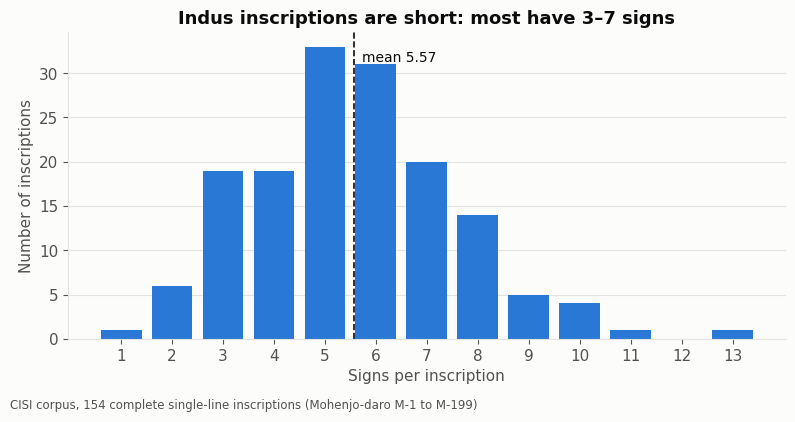

In [7]:
# --- 1a. Inscription length
complete = segments[segments.true_start & segments.true_end]
assert complete.text_id.is_unique                       # one segment per complete text
L = complete.length

# Milestone 1's way, for reconciliation: every slot of every text, P000 included
m1_way = raw.groupby('text_id').size()

length_table = pd.DataFrame({
    'Milestone 1 method (all 179 texts, P000 counted)': m1_way.describe()[['count', 'mean', '50%', 'min', 'max']],
    'Step 1 (154 complete single-line texts)': L.describe()[['count', 'mean', '50%', 'min', 'max']],
}).rename(index={'50%': 'median'}).round(2)
display(length_table)

fig, ax = plt.subplots(figsize=(8, 4.2))
counts = L.value_counts().sort_index()
ax.bar(counts.index, counts.values, width=0.8, color=BLUE)
ax.axvline(L.mean(), color=INK, lw=1.2, ls='--')
ax.text(L.mean() + 0.15, counts.max() * 0.95, f'mean {L.mean():.2f}', color=INK, fontsize=10)
ax.set_xticks(range(1, L.max() + 1))
ax.set_xlabel('Signs per inscription')
ax.set_ylabel('Number of inscriptions')
ax.set_title('Indus inscriptions are short: most have 3–7 signs')
ax.grid(axis='x', visible=False)
fig.text(0.01, 0.01, f'CISI corpus, {len(L)} complete single-line inscriptions (Mohenjo-daro M-1 to M-199)',
         fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f'{FIG_DIR}/m2_01_inscription_length.png', dpi=200)
plt.show()

In [8]:
# --- 1b. How unevenly signs are used: frequency, coverage, hapax
tokens = [s for seq in segments.signs for s in seq]
freq = pd.Series(collections.Counter(tokens)).sort_index().sort_values(ascending=False, kind='stable')   # ties broken by sign label, so the order is the same on every machine
assert freq.sum() == real_tokens == 984

cum = freq.cumsum() / freq.sum()
signs_for = lambda p: int((cum < p).sum() + 1)       # how many top signs reach p coverage
hapax = int((freq == 1).sum())

usage = pd.Series({
    'total sign occurrences': int(freq.sum()),
    'distinct signs': len(freq),
    'signs needed for 50% of occurrences': signs_for(0.50),
    'signs needed for 80% of occurrences': signs_for(0.80),
    'coverage of the top 67 signs (%)': round(100 * cum.iloc[66], 1),
    'signs seen exactly once (hapax)': hapax,
    'hapax as % of distinct signs': round(100 * hapax / len(freq), 1),
    'signs seen at most twice': int((freq <= 2).sum()),
})
display(usage.to_frame('value'))

top10 = pd.DataFrame({'count': freq.head(10), 'share %': (100 * freq.head(10) / freq.sum()).round(1)})
top10.index.name = 'sign'
display(top10)

,value
total sign occurrences,984.0
distinct signs,181.0
signs needed for 50% of occurrences,17.0
signs needed for 80% of occurrences,58.0
coverage of the top 67 signs (%),83.4
signs seen exactly once (hapax),77.0
hapax as % of distinct signs,42.5
signs seen at most twice,102.0


,count,share %
sign,,
P324,99,10.1
P122,76,7.7
P086,35,3.6
P385,35,3.6
P050,32,3.3
P145,27,2.7
P230,23,2.3
P120,22,2.2
P062,21,2.1


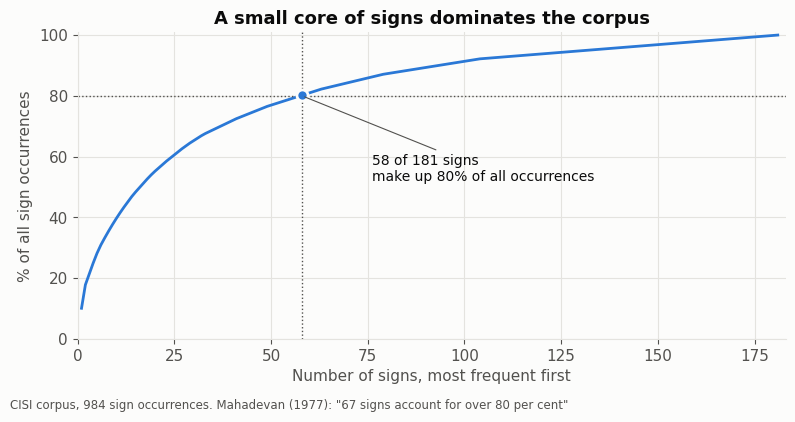

In [9]:
# --- 1c. Coverage curve (for the deck)
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(1, len(cum) + 1)
ax.plot(x, 100 * cum.values, color=BLUE, lw=2)
n80 = signs_for(0.80)
ax.axhline(80, color=INK2, lw=1, ls=':')
ax.axvline(n80, color=INK2, lw=1, ls=':')
ax.plot([n80], [100 * cum.iloc[n80 - 1]], 'o', color=BLUE, ms=8, mec=SURFACE, mew=2)
ax.annotate(f'{n80} of {len(freq)} signs\nmake up 80% of all occurrences',
            xy=(n80, 80), xytext=(n80 + 18, 52), color=INK, fontsize=10,
            arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.set_xlim(0, len(freq) + 2); ax.set_ylim(0, 101)
ax.set_xlabel('Number of signs, most frequent first')
ax.set_ylabel('% of all sign occurrences')
ax.set_title('A small core of signs dominates the corpus')
fig.text(0.01, 0.01, f'CISI corpus, {int(freq.sum())} sign occurrences. '
         'Mahadevan (1977): "67 signs account for over 80 per cent"', fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f'{FIG_DIR}/m2_02_sign_coverage.png', dpi=200)
plt.show()

In [10]:
# --- 1d. Reconciliation with Milestone 1
m1_freq = raw.sign.value_counts()                    # M1 counted P000 as a sign
m1_cov67 = m1_freq.head(67).sum() / m1_freq.sum()
recon = pd.DataFrame([
    ['Mean length',            '5.60', f'{m1_way.mean():.2f}', f'{L.mean():.2f}',
     'M1 averaged all 179 texts and counted P000; damaged texts look shorter, P000 adds slots'],
    ['Median length',          '5',    f'{m1_way.median():.0f}', f'{L.median():.0f}', ''],
    ['Distinct signs',         '182',  str(raw.sign.nunique()), str(len(freq)), 'P000 is no longer counted as a sign'],
    ['Top-67 coverage',        '83.4%', f'{100*m1_cov67:.1f}%', f'{100*cum.iloc[66]:.1f}%',
     'unchanged: removing 19 P000 tokens barely moves it (83.45% → 83.43%)'],
], columns=['measure', 'Milestone 1 report', 'M1 method re-run now', 'Step 1 (cleaned)', 'why it differs'])
display(recon.set_index('measure'))

,Milestone 1 report,M1 method re-run now,Step 1 (cleaned),why it differs
measure,,,,
Mean length,5.60,5.60,5.57,M1 averaged all 179 texts and counted P000; da...
Median length,5,5,5,
Distinct signs,182,182,181,P000 is no longer counted as a sign
Top-67 coverage,83.4%,83.4%,83.4%,unchanged: removing 19 P000 tokens barely move...


**Step 1 result.** See the reconciliation table. The Milestone 1 figures are reproduced exactly when the Milestone 1 method is re-run. The cleaned figures differ only for the documented reasons above, so Step 0 did not distort the data.

The hapax count shows how sparse the data is. A large share of signs occur only once, so their rows in the Markov matrix rest on a single observation. That is the problem Witten-Bell smoothing (Step 4) is designed to handle.

## Step 2 — Positional analysis: text beginners vs text enders

**Question:** do texts begin and end in systematically different ways? If the script had no fixed direction, the two ends of a text would be interchangeable, so the opening and closing signs would look alike. A strong difference between them is the statistical fingerprint of a **fixed writing direction**.

What we measure:
1. **Beginners and enders.** Taken only from *genuine* text edges (the `true_start` / `true_end` flags from Step 0).
2. **Positional profile.** For each frequent sign, the share of its appearances at the start, middle and end.
3. **Concentration of each end.** Number of distinct signs, the top sign's share, and the entropy (bits) of each distribution.
4. **Flip test.** Jensen–Shannon divergence (JSD) between the beginner and ender distributions, compared against 10,000 versions where each text's direction is decided by a coin toss.

> **Scope of the claim.** The statistics can show that the two ends differ, i.e. that the direction is *fixed*. Which end is the *start* comes from physical evidence (e.g. signs cramped at the left edge); here we test whether the numbers are consistent with right-to-left reading.

In [11]:
# --- 2a. Beginners and enders from genuine text edges
begin = pd.Series([s[0]  for s in segments.loc[segments.true_start, 'signs']]).value_counts()
end   = pd.Series([s[-1] for s in segments.loc[segments.true_end,   'signs']]).value_counts()

def top_table(vc, n=8):
    return pd.DataFrame({'sign': vc.index[:n], 'count': vc.values[:n],
                         'share %': (100 * vc.values[:n] / vc.sum()).round(1)})

side_by_side = pd.concat({f'BEGINNERS (n={begin.sum()})': top_table(begin),
                          f'ENDERS (n={end.sum()})': top_table(end)}, axis=1)
side_by_side.index = range(1, len(side_by_side) + 1)
display(side_by_side)

BEGINNERS (n=166)               ENDERS (n=161)              
               sign count share %           sign count share %
1              P385    29    17.5           P324    73    45.3
2              P378    10     6.0           P086    18    11.2
3              P256     9     5.4           P217    13     8.1
4              P011     5     3.0           P013     8     5.0
5              P123     5     3.0           P004     6     3.7
6              P226     4     2.4           P051     5     3.1
7              P230     4     2.4           P301     5     3.1
8              P145     4     2.4           P001     4     2.5

In [12]:
# --- 2b. Positional profile of frequent signs (complete single-line texts, length >= 2)
comp = [s for s in complete.signs if len(s) >= 2]
prof = collections.defaultdict(lambda: collections.Counter())
for s in comp:
    for i, sign in enumerate(s):
        prof[sign]['start' if i == 0 else 'end' if i == len(s) - 1 else 'middle'] += 1
prof = pd.DataFrame(prof).T.fillna(0).astype(int)[['start', 'middle', 'end']]
prof['total'] = prof.sum(axis=1)
for c in ['start', 'middle', 'end']:
    prof[c + ' %'] = (100 * prof[c] / prof.total).round(0).astype(int)
profile = prof[prof.total >= 10].sort_values('total', ascending=False)
display(profile[['total', 'start %', 'middle %', 'end %']])

# signs that live almost only at one end (>= 75% of their appearances, seen >= 5 times)
mostly = prof[prof.total >= 5]
print('Mostly at the START:', ', '.join(f"{i} ({r['start %']}% of {r.total})" for i, r in mostly[mostly['start %'] >= 75].iterrows()) or 'none')
print('Mostly at the END  :', ', '.join(f"{i} ({r['end %']}% of {r.total})" for i, r in mostly[mostly['end %'] >= 75].iterrows()) or 'none')

,total,start %,middle %,end %
P324,86,0,21,79
P122,65,0,100,0
P086,33,3,42,55
P385,28,86,14,0
P050,28,0,96,4
P145,23,13,87,0
P230,19,21,79,0
P120,18,0,100,0
P060,17,6,94,0
P062,17,0,100,0


Mostly at the START: P385 (86% of 28), P256 (78% of 9)
Mostly at the END  : P324 (79% of 86), P013 (100% of 8), P217 (87% of 15), P301 (83% of 6), P051 (100% of 5), P004 (100% of 6)


In [13]:
# --- 2c. How concentrated is each end?
def entropy_bits(vc):
    p = vc / vc.sum()
    return float(-(p * np.log2(p)).sum())

def wilson(k, n, z=1.96):          # 95% confidence interval for a proportion
    p = k / n; d = 1 + z**2 / n
    c = p + z**2 / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    return (c - h) / d, (c + h) / d

conc = pd.DataFrame({
    'genuine edges':           [begin.sum(), end.sum()],
    'distinct signs':          [len(begin), len(end)],
    'top sign':                [begin.index[0], end.index[0]],
    'top sign share %':        [round(100 * begin.iloc[0] / begin.sum(), 1), round(100 * end.iloc[0] / end.sum(), 1)],
    'top sign 95% CI':         ['{:.0f}–{:.0f}%'.format(*[100 * x for x in wilson(begin.iloc[0], begin.sum())]),
                                '{:.0f}–{:.0f}%'.format(*[100 * x for x in wilson(end.iloc[0], end.sum())])],
    'entropy (bits)':          [round(entropy_bits(begin), 2), round(entropy_bits(end), 2)],
}, index=['BEGINNINGS', 'ENDINGS'])
display(conc)

,genuine edges,distinct signs,top sign,top sign share %,top sign 95% CI,entropy (bits)
BEGINNINGS,166,86,P385,17.5,12–24%,5.63
ENDINGS,161,30,P324,45.3,38–53%,3.22


In [14]:
# --- 2d. The flip test: is the beginner/ender difference bigger than chance?
def jsd_bits(c1, c2):
    keys = sorted(set(c1) | set(c2))
    p = np.array([c1.get(k, 0) for k in keys], float); p /= p.sum()
    q = np.array([c2.get(k, 0) for k in keys], float); q /= q.sum()
    m = (p + q) / 2
    kl = lambda a, b: np.sum(a[a > 0] * np.log2(a[a > 0] / b[a > 0]))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

firsts = [s[0] for s in comp]; lasts = [s[-1] for s in comp]
observed = jsd_bits(collections.Counter(firsts), collections.Counter(lasts))

rng = np.random.default_rng(42)
N_PERM = 10_000
null = np.empty(N_PERM)
F, Lz = np.array(firsts), np.array(lasts)
for k in range(N_PERM):
    flip = rng.random(len(comp)) < 0.5                 # coin toss per text: read it the other way
    a = np.where(flip, Lz, F); b = np.where(flip, F, Lz)
    null[k] = jsd_bits(collections.Counter(a), collections.Counter(b))
p_value = (np.sum(null >= observed) + 1) / (N_PERM + 1)

print(f'texts used (complete, single-line, length >= 2): {len(comp)}')
print(f'observed beginner–ender divergence (JSD): {observed:.3f} bits')
print(f'random-direction divergence: mean {null.mean():.3f}, 99.9th percentile {np.percentile(null, 99.9):.3f}, max {null.max():.3f}')
print(f'p-value: {p_value:.5f}  (= none of the {N_PERM:,} random-direction versions reached the observed value)'
      if np.sum(null >= observed) == 0 else f'p-value: {p_value:.5f}')

texts used (complete, single-line, length >= 2): 153
observed beginner–ender divergence (JSD): 0.891 bits


random-direction divergence: mean 0.329, 99.9th percentile 0.402, max 0.418
p-value: 0.00010  (= none of the 10,000 random-direction versions reached the observed value)


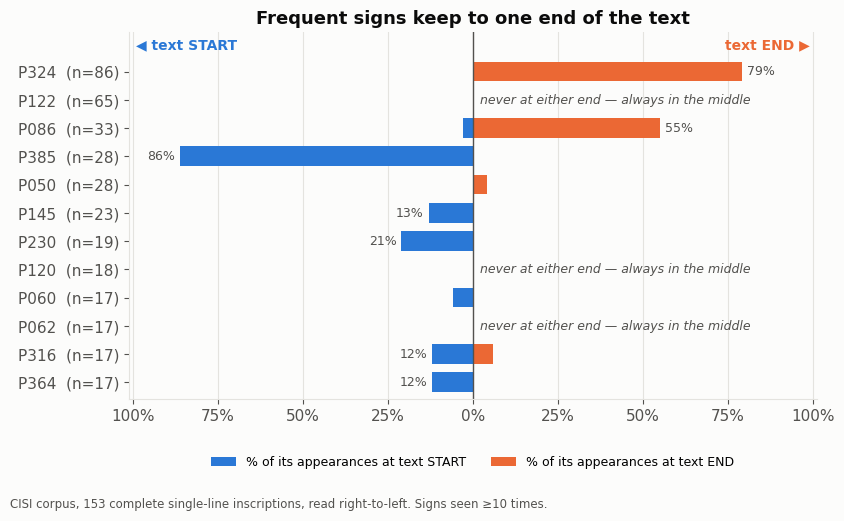

In [15]:
# --- 2e. Figure for the deck: where do the frequent signs sit?
ORANGE = '#eb6834'
show = profile.head(12).iloc[::-1]              # most frequent at the top
fig, ax = plt.subplots(figsize=(8.5, 5.2))
y = np.arange(len(show))
ax.barh(y, -show['start %'], color=BLUE, height=0.7, label='% of its appearances at text START')
ax.barh(y,  show['end %'],   color=ORANGE, height=0.7, label='% of its appearances at text END')
for yi, (sg, r) in zip(y, show.iterrows()):
    if r['start %'] >= 8: ax.text(-r['start %'] - 1.5, yi, f"{r['start %']}%", va='center', ha='right', fontsize=9, color=INK2)
    if r['end %']   >= 8: ax.text( r['end %']   + 1.5, yi, f"{r['end %']}%",   va='center', ha='left',  fontsize=9, color=INK2)
    if r['start %'] == 0 and r['end %'] == 0:
        ax.text(2, yi, 'never at either end — always in the middle', va='center', ha='left', fontsize=9,
                color=INK2, style='italic')
ax.set_yticks(y, [f'{s}  (n={int(r.total)})' for s, r in show.iterrows()])
ax.axvline(0, color=INK2, lw=1)
lim = max(show['start %'].max(), show['end %'].max()) + 15
ax.set_xlim(-lim, lim)
ax.set_xticks(np.arange(-100, 101, 25)); ax.set_xticklabels([f'{abs(t)}%' for t in np.arange(-100, 101, 25)])
ax.set_xlim(-lim, lim)
ax.grid(axis='y', visible=False)
ax.text(-lim + 2, len(show) - 0.3, '◀ text START', color=BLUE, fontsize=10, fontweight='bold', va='bottom')
ax.text( lim - 2, len(show) - 0.3, 'text END ▶',   color=ORANGE, fontsize=10, fontweight='bold', va='bottom', ha='right')
ax.set_ylim(-0.6, len(show) + 0.4)
ax.set_title('Frequent signs keep to one end of the text')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False, fontsize=9)
fig.text(0.01, 0.01, f'CISI corpus, {len(comp)} complete single-line inscriptions, read right-to-left. '
         'Signs seen ≥10 times.', fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f'{FIG_DIR}/m2_03_start_vs_end.png', dpi=200)
plt.show()

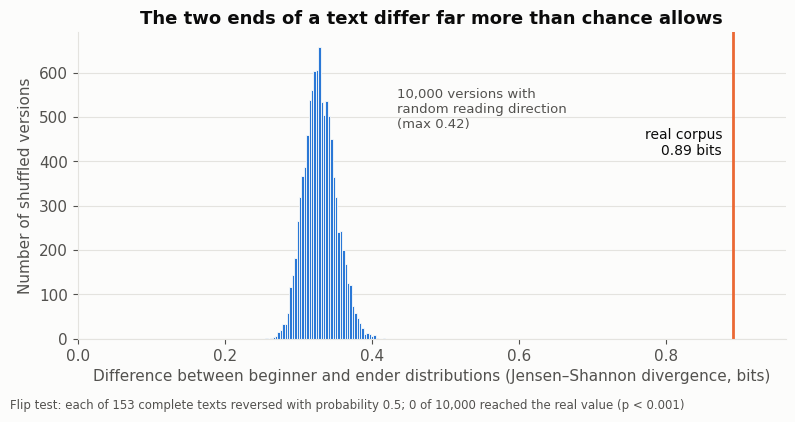

In [16]:
# --- 2f. Figure for the deck: the flip test
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(null, bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.axvline(observed, color=ORANGE, lw=2)
ytop = ax.get_ylim()[1]
ax.text(observed - 0.015, ytop * 0.6, f'real corpus\n{observed:.2f} bits', ha='right', color=INK, fontsize=10)
ax.text(null.max() + 0.015, ytop * 0.75, f'{N_PERM:,} versions with\nrandom reading direction\n(max {null.max():.2f})',
        ha='left', color=INK2, fontsize=9.5, va='center')
ax.set_xlim(0, max(observed, null.max()) * 1.08)
ax.set_xlabel('Difference between beginner and ender distributions (Jensen–Shannon divergence, bits)')
ax.set_ylabel('Number of shuffled versions')
ax.grid(axis='x', visible=False)
ax.set_title('The two ends of a text differ far more than chance allows')
fig.text(0.01, 0.01, f'Flip test: each of {len(comp)} complete texts reversed with probability 0.5; '
         f'0 of {N_PERM:,} reached the real value (p < 0.001)', fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f'{FIG_DIR}/m2_04_flip_test.png', dpi=200)
plt.show()

**Step 2 result.** See the tables and figures above. Texts begin and end in clearly different ways, and the flip test shows the difference is far beyond what random reading direction produces. The script therefore has a **fixed writing direction**. Under the right-to-left reading, one sign (`P324`) dominates the text endings, and that pattern is analysed further with the Markov matrix in Steps 3–5.

## Step 3 — Transition counts and the Markov chain matrix

A **first-order Markov chain** (a bigram model) assumes that *the next sign depends only on the current sign*. Its matrix has:
- **rows** = the current sign;
- **columns** = the next sign;
- **cells** = $P(\text{next} \mid \text{current})$, with each row summing to 1.

Two boundary markers are added, following the Step 0 rules:
- `<S>` (START) goes before every **genuine** text beginning. The `<S>` row is therefore the distribution of text openers.
- `</S>` (END) goes after every **genuine** text ending. The `</S>` column is therefore the probability that a text stops after a given sign.
- Edges next to damage or a line break get no marker.

In this step the probabilities are the plain **maximum-likelihood estimate (MLE)**: count ÷ row total. MLE gives probability **0** to every unseen pair. That problem is measured here and fixed by smoothing in Step 4.

In [17]:
# --- 3a. Count every transition, including the START/END markers
START, END = '<S>', '</S>'

def transitions(segs):
    # yield (current, next) pairs in reading order, with START/END only at genuine edges
    for _, r in segs.iterrows():
        seq = ([START] if r.true_start else []) + list(r.signs) + ([END] if r.true_end else [])
        yield from zip(seq[:-1], seq[1:])

pairs = list(transitions(segments))
signs_sorted = list(freq.index)                       # most frequent first (from Step 1)
row_labels = [START] + signs_sorted
col_labels = signs_sorted + [END]

counts = pd.DataFrame(0, index=row_labels, columns=col_labels, dtype=int)
for a, b in pairs:
    counts.at[a, b] += 1

n_sign_pairs = sum(1 for a, b in pairs if a != START and b != END)
n_starts = int(counts.loc[START].sum()); n_ends = int(counts[END].sum())
print(f'transitions counted: {len(pairs)}  = {n_sign_pairs} sign→sign + {n_starts} START→sign + {n_ends} sign→END')
assert n_sign_pairs == 796 and n_starts == 166 and n_ends == 161, 'must match Step 0 exactly'
assert counts.values.sum() == len(pairs)
print('matrix shape (rows × cols):', counts.shape)

transitions counted: 1123  = 796 sign→sign + 166 START→sign + 161 sign→END
matrix shape (rows × cols): (182, 182)


In [18]:
# --- 3b. Maximum-likelihood probabilities: count / row total
row_tot = counts.sum(axis=1)
active = row_tot > 0                                  # signs with at least one observed successor
P_mle = counts[active].div(row_tot[active], axis=0)
assert np.allclose(P_mle.sum(axis=1), 1.0), 'every row must sum to 1'

no_successor = list(row_tot[~active].index)
print(f'rows with at least one observed successor: {active.sum()} of {len(row_tot)}')
print(f'signs never seen followed by anything ({len(no_successor)}): '
      'they only occur right before damage or a line break')

rows with at least one observed successor: 177 of 182
signs never seen followed by anything (5): they only occur right before damage or a line break


In [19]:
# --- 3c. How sparse is the matrix? (the zero problem)
possible = counts.shape[0] * counts.shape[1]
observed_cells = int((counts > 0).values.sum())
rows_n = row_tot[active]
sparsity = pd.Series({
    'possible cells (rows × cols)': possible,
    'cells ever observed': observed_cells,
    'observed cells as % of possible': round(100 * observed_cells / possible, 2),
    'cells MLE sets to exactly 0 (%)': round(100 * (1 - observed_cells / possible), 2),
    'rows built from a single observation': int((rows_n == 1).sum()),
    'rows built from ≤ 3 observations': int((rows_n <= 3).sum()),
    'rows where MLE is 100% certain of the next sign': int((P_mle.max(axis=1) == 1).sum()),
})
display(sparsity.to_frame('value'))

,value
possible cells (rows × cols),33124.00
cells ever observed,645.00
observed cells as % of possible,1.95
cells MLE sets to exactly 0 (%),98.05
rows built from a single observation,73.00
rows built from ≤ 3 observations,113.00
rows where MLE is 100% certain of the next sign,84.00


In [20]:
# --- 3d. The strongest pairings
pair_tab = (counts.stack().rename('count').reset_index()
            .rename(columns={'level_0': 'current', 'level_1': 'next'}))
pair_tab = pair_tab[pair_tab['count'] > 0].copy()
pair_tab['P(next | current)'] = pair_tab.apply(lambda r: r['count'] / row_tot[r.current], axis=1).round(2)
pair_tab['current seen'] = pair_tab.current.map(row_tot)

print('Most frequent sign → sign pairs (reading order):')
display(pair_tab[(pair_tab.current != START) & (pair_tab.next != END)]
        .sort_values('count', ascending=False).head(12).reset_index(drop=True))

print('Most predictable rules — P(next | current) among signs seen ≥ 8 times:')
display(pair_tab[(pair_tab['current seen'] >= 8)]
        .sort_values(['P(next | current)', 'count'], ascending=False).head(12).reset_index(drop=True))

Most frequent sign → sign pairs (reading order):


,current,next,count,P(next | current),current seen
0,P385,P122,28,0.85,33
1,P332,P324,10,1.00,10
2,P316,P147,10,0.56,18
3,P122,P364,9,0.12,72
4,P060,P062,9,0.45,20
5,P324,P013,9,0.10,94
6,P145,P050,8,0.31,26
7,P256,P120,7,0.58,12
8,P122,P145,7,0.10,72
9,P050,P217,6,0.19,32


Most predictable rules — P(next | current) among signs seen ≥ 8 times:


,current,next,count,P(next | current),current seen
0,P332,P324,10,1.00,10
1,P013,</S>,8,1.00,8
2,P385,P122,28,0.85,33
3,P324,</S>,73,0.78,94
4,P217,</S>,13,0.76,17
5,P256,P120,7,0.58,12
6,P316,P147,10,0.56,18
7,P086,</S>,18,0.53,34
8,P205,P122,5,0.50,10
9,P194,P324,4,0.50,8


In [21]:
# --- 3e. What comes before the dominant ender P324?  (column view of the matrix)
before_324 = counts['P324'][counts['P324'] > 0].sort_index().sort_values(ascending=False, kind='stable')
print(f'P324 occurs {int(freq["P324"])} times. Its predecessors (reading order: X → P324):')
display(pd.DataFrame({'count': before_324.head(8),
                      'share of observed predecessors %': (100 * before_324.head(8) / before_324.sum()).round(1)}))
after_324 = counts.loc['P324'][counts.loc['P324'] > 0].sort_index().sort_values(ascending=False, kind='stable')
print('What follows P324:', ', '.join(f'{k} ({v})' for k, v in after_324.items()))

P324 occurs 99 times. Its predecessors (reading order: X → P324):


,count,share of observed predecessors %
P332,10,10.3
P086,5,5.2
P175,5,5.2
P009,4,4.1
P154,4,4.1
P194,4,4.1
P050,3,3.1
P073,3,3.1


What follows P324: </S> (73), P013 (9), P060 (2), P011 (1), P103 (1), P121 (1), P204 (1), P210 (1), P238 (1), P324 (1), P341 (1), P364 (1), P385 (1)


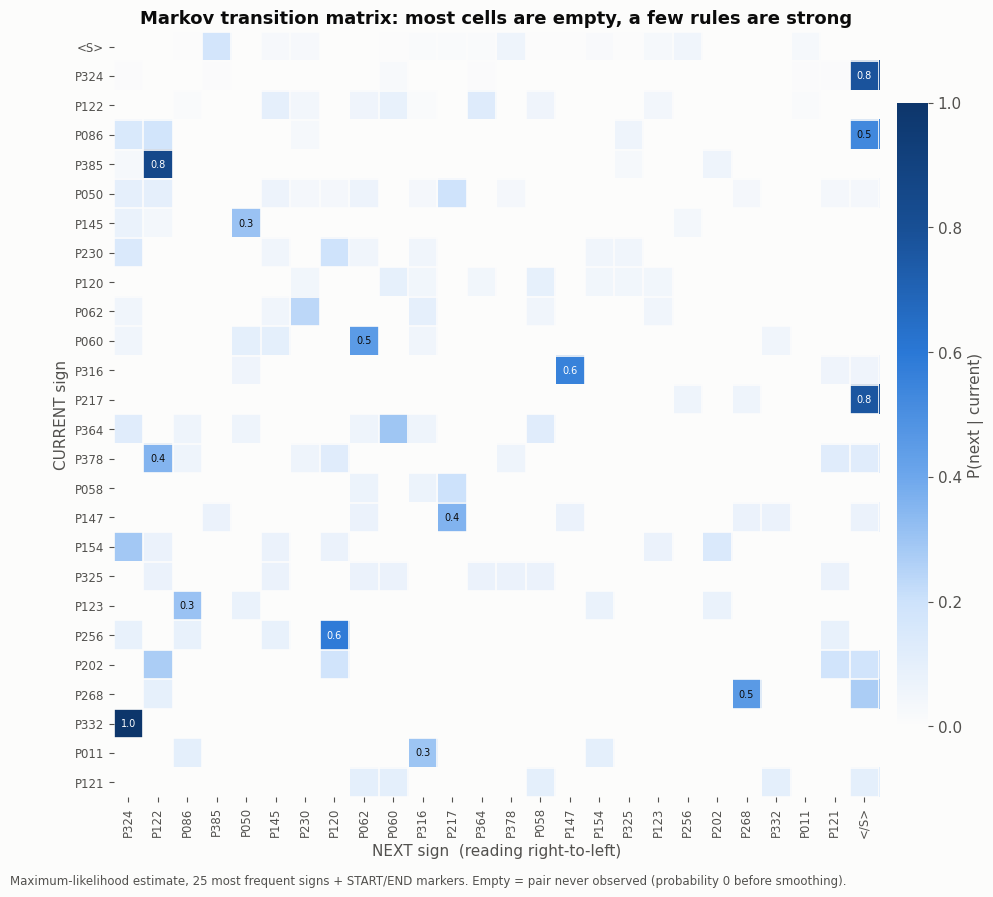

In [22]:
# --- 3f. Heatmap of the matrix for the 25 most frequent signs (for the deck)
from matplotlib.colors import LinearSegmentedColormap
top = signs_sorted[:25]
H = P_mle.reindex(index=[START] + top, columns=top + [END]).fillna(0)
cmap = LinearSegmentedColormap.from_list('blue_seq', [SURFACE, '#cde2fb', '#6da7ec', '#2a78d6', '#184f95', '#0d366b'])

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(H.values, cmap=cmap, vmin=0, vmax=1, aspect='equal')
ax.set_xticks(range(H.shape[1]), H.columns, rotation=90, fontsize=8.5)
ax.set_yticks(range(H.shape[0]), H.index, fontsize=8.5)
ax.set_xlabel('NEXT sign  (reading right-to-left)')
ax.set_ylabel('CURRENT sign')
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_xticks(np.arange(-.5, H.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, H.shape[0]), minor=True)
ax.grid(which='minor', color=SURFACE, linewidth=1.2); ax.tick_params(which='minor', length=0)
for (i, j), v in np.ndenumerate(H.values):           # label only the strong cells
    if v >= 0.3:
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=7, color='white' if v > 0.55 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.set_label('P(next | current)', color=INK2)
cb.outline.set_visible(False)
ax.set_title('Markov transition matrix: most cells are empty, a few rules are strong')
fig.text(0.01, 0.01, 'Maximum-likelihood estimate, 25 most frequent signs + START/END markers. '
         'Empty = pair never observed (probability 0 before smoothing).', fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(f'{FIG_DIR}/m2_05_markov_matrix_mle.png', dpi=200)
plt.show()

In [23]:
# --- 3g. Save the matrices
counts.to_csv(f'{OUT_DIR}/markov_counts.csv')
P_mle.to_csv(f'{OUT_DIR}/markov_mle.csv', float_format='%.4f')
print('saved: outputs/markov_counts.csv, outputs/markov_mle.csv')

saved: outputs/markov_counts.csv, outputs/markov_mle.csv


**Step 3 result.** The transition matrix is built and checked: every row sums to 1, and the counts reconcile exactly with Step 0. It is **extremely sparse**. Only a small fraction of possible pairs were ever observed, and many rows rest on one or two observations, where MLE is unjustifiably certain. Step 4 applies Witten-Bell smoothing to give unseen pairs a principled, non-zero probability.

## Step 4 — Witten-Bell smoothing for unseen pairings

**Problem (from Step 3).** MLE gives probability 0 to 98% of pairs and is "100% certain" for rows seen once. A single unseen pair in a new inscription therefore gives that inscription probability 0 (log 0 = −∞).

**Witten-Bell (1991)** interpolates each row with a lower-order distribution. How much weight goes to the lower order is set by how *varied* the row already is:

$$P_{WB}(w \mid h) = \frac{C(h,w) + T(h)\,P_{\text{uni}}(w)}{C(h) + T(h)}$$

- $C(h,w)$ = count of the pair $h \to w$.
- $C(h)$ = row total.
- $T(h)$ = number of **distinct** successors of $h$.
- The share reserved for unseen successors is $\frac{T(h)}{C(h)+T(h)}$. Rows with thin or highly varied evidence reserve more; well-observed, consistent rows reserve little.
- $P_{\text{uni}}(w)$ is the overall successor frequency. It is itself Witten-Bell–interpolated with a uniform distribution, so that no sign gets 0.
- Rows with no observations ($C(h)=0$) fall back fully to $P_{\text{uni}}$.

**Vocabulary.** The 181 signs + END (columns) and START + 181 signs (rows) are fixed from the full corpus (closed-vocabulary assumption).

**Validation.** 10-fold cross-validation **by inscription**: fit on 90% of the texts, score the held-out 10%. Three methods are compared: MLE, add-one (Laplace) and Witten-Bell. The score is **perplexity**, $2^{H}$, where $H$ is the average −log₂ probability per held-out transition. Lower is better.

In [24]:
# --- 4a. Reusable model functions (also used in Steps 5 and 7)
ROWS = [START] + signs_sorted            # fixed vocabulary
COLS = signs_sorted + [END]
r_ix = {s: i for i, s in enumerate(ROWS)}
c_ix = {s: i for i, s in enumerate(COLS)}
V = len(COLS)

def count_matrix(segs):
    M = np.zeros((len(ROWS), len(COLS)))
    for a, b in transitions(segs):
        M[r_ix[a], c_ix[b]] += 1
    return M

def p_unigram_wb(M):
    # successor distribution, Witten-Bell–interpolated with uniform so nothing is 0
    n_col = M.sum(axis=0); N = n_col.sum(); T = (n_col > 0).sum()
    return (n_col + T / V) / (N + T)

def witten_bell(M):
    p_uni = p_unigram_wb(M)
    c = M.sum(axis=1, keepdims=True); t = (M > 0).sum(axis=1, keepdims=True)
    with np.errstate(invalid='ignore', divide='ignore'):
        P = (M + t * p_uni) / (c + t)
    P[c[:, 0] == 0] = p_uni                    # unseen row → back off completely
    return P

def laplace(M):
    return (M + 1) / (M.sum(axis=1, keepdims=True) + V)

def mle(M):
    c = M.sum(axis=1, keepdims=True)
    with np.errstate(invalid='ignore', divide='ignore'):
        P = np.where(c > 0, M / c, 0.0)
    return P

def evaluate(P, segs):
    # average −log2 probability per transition, perplexity, and number of zero-probability events
    lp, zeros, n = 0.0, 0, 0
    for a, b in transitions(segs):
        p = P[r_ix[a], c_ix[b]]; n += 1
        if p <= 0: zeros += 1
        else: lp += -np.log2(p)
    H = np.inf if zeros else lp / n
    return dict(transitions=n, zero_prob_events=zeros, bits_per_transition=H, perplexity=2 ** H)

In [25]:
# --- 4b. Fit Witten-Bell on the full corpus and verify it
M_full = count_matrix(segments)
assert M_full.sum() == 1123 and np.array_equal(M_full, counts.reindex(index=ROWS, columns=COLS).values)
P_wb = witten_bell(M_full)

assert np.allclose(P_wb.sum(axis=1), 1.0), 'every row must sum to 1'
assert (P_wb > 0).all(), 'no cell may be 0'
print('Witten-Bell matrix:', P_wb.shape, '| rows sum to 1 ✓ | smallest cell = {:.2e} (> 0) ✓'.format(P_wb.min()))

c_row = M_full.sum(axis=1); t_row = (M_full > 0).sum(axis=1)
reserved = np.divide(t_row, c_row + t_row, out=np.ones_like(c_row), where=c_row > 0)   # empty rows: 100%
res = pd.DataFrame({'C (observations)': c_row.astype(int), 'T (distinct successors)': t_row,
                    'reserved for unseen %': (100 * reserved).round(1)}, index=ROWS)
display(res.loc[[START, 'P324', 'P122', 'P385', 'P332', 'P013']]
        .rename(index={START: '<S> (text openers)'}))
print('rows with a single observation reserve:', sorted(set(res.loc[res['C (observations)'] == 1, 'reserved for unseen %'])), '%')

Witten-Bell matrix: (182, 182) | rows sum to 1 ✓ | smallest cell = 6.83e-05 (> 0) ✓


,C (observations),T (distinct successors),reserved for unseen %
<S> (text openers),166,86,34.1
P324,94,13,12.1
P122,72,34,32.1
P385,33,5,13.2
P332,10,1,9.1
P013,8,1,11.1


rows with a single observation reserve: [50.0] %


In [26]:
# --- 4c. Before / after: what smoothing does to individual rows
def compare_row(sign, k=5):
    i = r_ix[sign]
    order = np.argsort(-P_wb[i])[:k]
    mle_row = mle(M_full)[i]
    t = pd.DataFrame({'next': [COLS[j] for j in order],
                      'count': M_full[i, order].astype(int),
                      'MLE': mle_row[order].round(3),
                      'Witten-Bell': P_wb[i, order].round(3)})
    unseen = M_full[i] == 0
    print(f'{sign}: seen {int(c_row[i])}× with {t_row[i]} distinct successors | '
          f'unseen successors: MLE total = {mle_row[unseen].sum():.3f}, Witten-Bell total = {P_wb[i, unseen].sum():.3f}')
    display(t)

compare_row('P385')                                    # well observed, consistent
one_obs = res[res['C (observations)'] == 1].index[0]
compare_row(one_obs)                                   # a row built from one observation

P385: seen 33× with 5 distinct successors | unseen successors: MLE total = 0.000, Witten-Bell total = 0.111


,next,count,MLE,Witten-Bell
0,P122,28,0.848,0.744
1,P202,2,0.061,0.054
2,P324,1,0.030,0.036
3,P325,1,0.030,0.028
4,P125,1,0.030,0.027


P265: seen 1× with 1 distinct successors | unseen successors: MLE total = 0.000, Witten-Bell total = 0.462


,next,count,MLE,Witten-Bell
0,P324,1,1.0,0.538
1,</S>,0,0.0,0.062
2,P122,0,0.0,0.028
3,P086,0,0.0,0.014
4,P385,0,0.0,0.013


In [27]:
# --- 4d. Does smoothing help? 10-fold cross-validation by inscription
from itertools import chain
text_ids = segments.text_id.unique()
rng = np.random.default_rng(42)
folds = np.array_split(rng.permutation(text_ids), 10)

results = []
for k, test_ids in enumerate(folds):
    train = segments[~segments.text_id.isin(test_ids)]
    test  = segments[ segments.text_id.isin(test_ids)]
    M = count_matrix(train)
    for name, fn in [('MLE (no smoothing)', mle), ('Add-one (Laplace)', laplace), ('Witten-Bell', witten_bell)]:
        results.append(dict(fold=k, method=name, **evaluate(fn(M), test)))
cv = pd.DataFrame(results)

def summarise(g):
    finite = g[np.isfinite(g.bits_per_transition)]
    return pd.Series({
        'held-out transitions': int(g.transitions.sum()),
        'zero-probability events': int(g.zero_prob_events.sum()),
        'folds where model fails (−∞)': int((~np.isfinite(g.bits_per_transition)).sum()),
        'bits / transition (mean)': round(finite.bits_per_transition.mean(), 2) if len(finite) else np.inf,
        'perplexity (mean)': round(finite.perplexity.mean(), 1) if len(finite) else np.inf,
        'perplexity (fold min–max)': f'{finite.perplexity.min():.1f}–{finite.perplexity.max():.1f}' if len(finite) else '∞',
    })
cv_summary = cv.groupby('method', sort=False).apply(summarise)
display(cv_summary)
print(f'Reference: a model guessing uniformly among {V} choices has perplexity {V}.')

/sessions/rcw-01kgwsngicncmv17twejjspe/tmp/ipykernel_11/4045160550.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cv_summary = cv.groupby('method', sort=False).apply(summarise)


,held-out transitions,zero-probability events,folds where model fails (−∞),bits / transition (mean),perplexity (mean),perplexity (fold min–max)
method,,,,,,
MLE (no smoothing),1123,516,10,inf,inf,∞
Add-one (Laplace),1123,0,0,6.27,77.3,71.4–84.7
Witten-Bell,1123,0,0,5.34,40.8,33.6–48.2


Reference: a model guessing uniformly among 182 choices has perplexity 182.


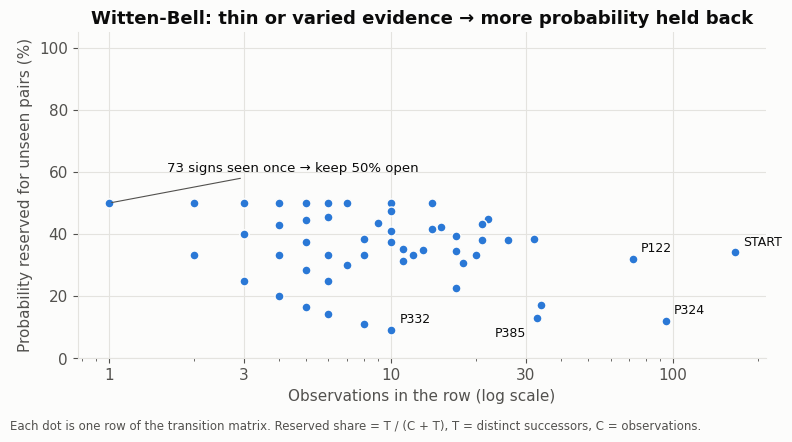

In [28]:
# --- 4e. Figure for the deck: how much each row reserves for unseen pairs
fig, ax = plt.subplots(figsize=(8, 4.4))
mask = c_row > 0
ax.scatter(c_row[mask], 100 * reserved[mask], s=42, color=BLUE, edgecolor=SURFACE, linewidth=1, zorder=3)
ax.set_xscale('log')
offsets = {'P324': (6, 5), 'P122': (6, 5), 'P385': (-8, -14), 'P332': (6, 5), START: (6, 5)}
for s, off in offsets.items():
    i = r_ix[s]
    lab = 'START' if s == START else s
    ax.annotate(lab, (c_row[i], 100 * reserved[i]), xytext=off, textcoords='offset points', fontsize=9,
                color=INK, ha='right' if off[0] < 0 else 'left')
from matplotlib.ticker import FixedLocator, FixedFormatter
ax.xaxis.set_major_locator(FixedLocator([1, 3, 10, 30, 100]))
ax.xaxis.set_major_formatter(FixedFormatter(['1', '3', '10', '30', '100']))
n1 = int((c_row == 1).sum())
ax.annotate(f'{n1} signs seen once → keep 50% open', (1, 50), xytext=(1.6, 60), fontsize=9.5, color=INK,
            arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.set_xlabel('Observations in the row (log scale)')
ax.set_ylabel('Probability reserved for unseen pairs (%)')
ax.set_ylim(0, 105)
ax.set_title('Witten-Bell: thin or varied evidence → more probability held back')
fig.text(0.01, 0.01, 'Each dot is one row of the transition matrix. Reserved share = T / (C + T), '
         'T = distinct successors, C = observations.', fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f'{FIG_DIR}/m2_06_witten_bell_reserve.png', dpi=200)
plt.show()

In [29]:
# --- 4f. Save the smoothed matrix (the main deliverable matrix)
P_wb_df = pd.DataFrame(P_wb, index=ROWS, columns=COLS)
P_wb_df.to_csv(f'{OUT_DIR}/markov_witten_bell.csv', float_format='%.6f')
print('saved: outputs/markov_witten_bell.csv', P_wb_df.shape)

saved: outputs/markov_witten_bell.csv (182, 182)


**Step 4 result.** The Witten-Bell matrix has no zeros, and every row sums to 1. Well-observed rows stay close to their counts, while thin rows are pulled toward the overall distribution. On held-out inscriptions, plain MLE fails outright (unseen pairs get probability 0), and Witten-Bell gives the lowest perplexity of the three methods. That justifies the proposal's choice of smoothing, and this matrix is used in Steps 5–7.

## Step 5 — Directional tests and the directional rules matrix

### 5a. The trap: a bigram model's overall score cannot detect direction
The obvious test, *"train left-to-right and right-to-left models and see which predicts better"*, does not work for a bigram model with boundary markers. The likelihood of a text is

$$P(\text{text}) = \prod_t \frac{C(x_t, x_{t+1})}{C(x_t)}$$

Reversing the text uses exactly the same pair counts, only flipped, and the same sign counts. On training data the two directions therefore give **identical** scores, and on held-out data they differ only by smoothing noise. The overall perplexity is blind to direction, however strong the real direction is. We show this explicitly so that it is never claimed as evidence (a point that carries over to Milestone 4).

In [30]:
# --- 5a. Forward vs backward models
def reverse_segments(segs):
    # read every segment the other way: reverse the signs and swap the genuine-edge flags
    return segs.assign(signs=segs.signs.apply(lambda s: s[::-1]),
                       true_start=segs.true_end, true_end=segs.true_start)

segments_ltr = reverse_segments(segments)

# (i) training data, plain MLE, complete texts only
comp_df = segments[segments.true_start & segments.true_end]
train_rtl = evaluate(mle(count_matrix(comp_df)), comp_df)
train_ltr = evaluate(mle(count_matrix(reverse_segments(comp_df))), reverse_segments(comp_df))

# (ii) held-out data, Witten-Bell, the same 10 folds as Step 4
def cv_perplexity(segs):
    lp, n = 0.0, 0
    for test_ids in folds:
        tr_, te_ = segs[~segs.text_id.isin(test_ids)], segs[segs.text_id.isin(test_ids)]
        r = evaluate(witten_bell(count_matrix(tr_)), te_)
        lp += r['bits_per_transition'] * r['transitions']; n += r['transitions']
    return lp / n

cv_rtl, cv_ltr = cv_perplexity(segments), cv_perplexity(segments_ltr)
trap = pd.DataFrame({
    'training data, MLE (bits / transition)': [train_rtl['bits_per_transition'], train_ltr['bits_per_transition']],
    'held-out, Witten-Bell (bits / transition)': [cv_rtl, cv_ltr],
    'held-out perplexity': [2 ** cv_rtl, 2 ** cv_ltr],
}, index=['right-to-left (as read)', 'left-to-right (reversed)']).round(4)
display(trap)
assert np.isclose(train_rtl['bits_per_transition'], train_ltr['bits_per_transition']), 'identity must hold exactly'
print(f'Training scores identical: ✓   held-out difference: {abs(2**cv_rtl - 2**cv_ltr):.2f} perplexity points '
      f'({100*abs(2**cv_rtl - 2**cv_ltr)/2**cv_rtl:.1f}%) — noise, not evidence')

,"training data, MLE (bits / transition)","held-out, Witten-Bell (bits / transition)",held-out perplexity
right-to-left (as read),2.5861,5.3373,40.4281
left-to-right (reversed),2.5861,5.3358,40.3858


Training scores identical: ✓   held-out difference: 0.04 perplexity points (0.1%) — noise, not evidence


### 5b. A direction test that works: position-by-position predictability
Align all complete texts (length ≥ 4) by their **first** sign and measure the entropy of the sign at positions 1–4. Then align them by their **last** sign and do the same. If direction did not matter, the two profiles would be interchangeable.

As in Step 2, the baseline comes from 10,000 versions in which each text's direction is decided by a coin toss. The shaded band in the figure is the range those random versions produce (2.5–97.5%).

In [31]:
# --- 5b. Positional entropy profile with a random-direction baseline
def H_bits(items):
    c = np.array(list(collections.Counter(items).values()), float); p = c / c.sum()
    return float(-(p * np.log2(p)).sum())

K = 4
texts4 = [s for s in complete.signs if len(s) >= K]
from_start = [H_bits([s[k] for s in texts4]) for k in range(K)]
from_end   = [H_bits([s[-1 - k] for s in texts4]) for k in range(K)]

rng = np.random.default_rng(7)
null_prof = np.empty((N_PERM, K))
null_gap1 = np.empty(N_PERM)
for i in range(N_PERM):
    flip = rng.random(len(texts4)) < 0.5
    oriented = [s[::-1] if f else s for s, f in zip(texts4, flip)]
    a = [H_bits([s[k] for s in oriented]) for k in range(K)]
    b = H_bits([s[-1] for s in oriented])
    null_prof[i] = a
    null_gap1[i] = abs(a[0] - b)
gap1 = abs(from_start[0] - from_end[0])
p_gap1 = (np.sum(null_gap1 >= gap1) + 1) / (N_PERM + 1)
lo, hi = np.percentile(null_prof, [2.5, 97.5], axis=0)

prof_tab = pd.DataFrame({'aligned by FIRST sign': from_start, 'aligned by LAST sign': from_end,
                         'random-direction range': [f'{l:.2f}–{h:.2f}' for l, h in zip(lo, hi)]},
                        index=[f'position {k+1}' for k in range(K)]).round(2)
print(f'texts used (complete, single-line, length ≥ {K}): {len(texts4)}   (entropy in bits; lower = more predictable)')
display(prof_tab)
print(f'Position-1 gap: {gap1:.2f} bits.  Random-direction max: {null_gap1.max():.2f}.  p < {max(p_gap1, 1/N_PERM):.4f}')

texts used (complete, single-line, length ≥ 4): 128   (entropy in bits; lower = more predictable)


,aligned by FIRST sign,aligned by LAST sign,random-direction range
position 1,5.31,2.94,4.36–5.04
position 2,4.80,5.60,5.25–5.68
position 3,5.32,5.20,5.10–5.47
position 4,5.38,5.01,5.10–5.47


Position-1 gap: 2.37 bits.  Random-direction max: 1.29.  p < 0.0001


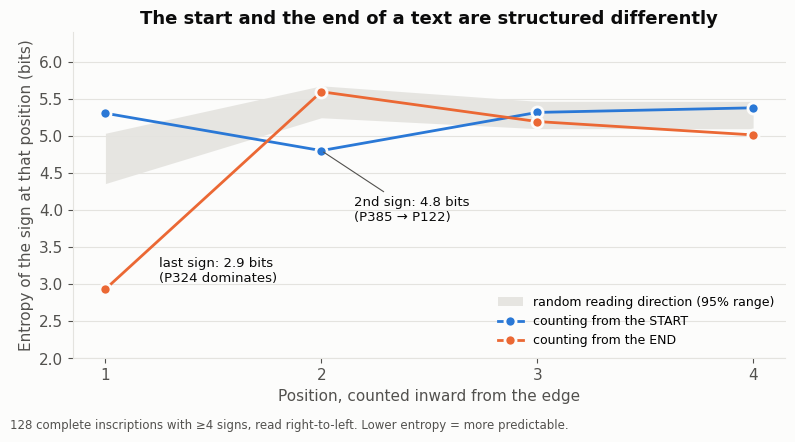

In [32]:
# --- 5c. Figure for the deck
fig, ax = plt.subplots(figsize=(8, 4.4))
x = np.arange(1, K + 1)
ax.fill_between(x, lo, hi, color=GRID, alpha=0.9, lw=0, label='random reading direction (95% range)')
ax.plot(x, from_start, '-o', color=BLUE, lw=2, ms=8, mec=SURFACE, mew=2, label='counting from the START')
ax.plot(x, from_end,   '-o', color=ORANGE, lw=2, ms=8, mec=SURFACE, mew=2, label='counting from the END')
ax.annotate(f'last sign: {from_end[0]:.1f} bits\n(P324 dominates)', (1, from_end[0]), xytext=(1.25, from_end[0] + 0.05),
            fontsize=9.5, color=INK, va='bottom')
ax.annotate(f'2nd sign: {from_start[1]:.1f} bits\n(P385 → P122)', (2, from_start[1]), xytext=(2.15, from_start[1] - 0.95),
            fontsize=9.5, color=INK, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.set_xticks(x, [f'{k}' for k in x])
ax.set_xlabel('Position, counted inward from the edge')
ax.set_ylabel('Entropy of the sign at that position (bits)')
ax.set_ylim(2, 6.4)
ax.grid(axis='x', visible=False)
ax.legend(loc='lower right', frameon=False, fontsize=9)
ax.set_title('The start and the end of a text are structured differently')
fig.text(0.01, 0.01, f'{len(texts4)} complete inscriptions with ≥{K} signs, read right-to-left. '
         'Lower entropy = more predictable.', fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f'{FIG_DIR}/m2_07_positional_entropy.png', dpi=200)
plt.show()

### 5c. The directional rules matrix
For every sign seen at least 8 times in complete texts, we compare how often it stands at the **start** and at the **end** with how often it would if position did not matter. Each text has exactly one first and one last sign, so the chance rate is (number of texts) ÷ (number of signs).

- **Test:** two-sided binomial test, with the Benjamini–Hochberg correction across all tests (q < 0.05), so that rules produced by chance are filtered out.
- **Roles:**
  - **opener**: significantly over-represented at the start;
  - **ender**: significantly over-represented at the end;
  - **medial**: significantly *avoids* both edges;
  - **no clear preference**: none of the above.
- **Strongest next sign:** taken from the Witten-Bell matrix of Step 4.

In [33]:
# --- 5d. Directional rules with significance testing
from scipy.stats import binomtest

def bh(pvals):                                   # Benjamini–Hochberg adjusted p-values (q-values)
    p = np.asarray(pvals); n = len(p); order = np.argsort(p)
    q = np.empty(n); prev = 1.0
    for rank, i in reversed(list(enumerate(order, start=1))):
        prev = min(prev, p[i] * n / rank); q[i] = prev
    return q

n_texts = len(comp); n_tok = sum(len(s) for s in comp)
p_edge = n_texts / n_tok                          # chance that a random token is a text's first (or last) sign
cand = prof[prof.total >= 8].copy()
cand['edge'] = cand.start + cand.end
tests = []
for s, r in cand.iterrows():
    tests += [(s, 'start', binomtest(int(r.start), int(r.total), p_edge).pvalue),
              (s, 'end',   binomtest(int(r.end),   int(r.total), p_edge).pvalue),
              (s, 'edge',  binomtest(int(r.edge),  int(r.total), 2 * p_edge).pvalue)]
tdf = pd.DataFrame(tests, columns=['sign', 'test', 'p']); tdf['q'] = bh(tdf.p)
Q = tdf.pivot(index='sign', columns='test', values='q').reindex(cand.index)   # same row order as cand

def role(s):
    r = cand.loc[s]; exp = p_edge * r.total
    roles = []
    if Q.at[s, 'start'] < 0.05 and r.start > exp: roles.append('OPENER')
    if Q.at[s, 'end']   < 0.05 and r.end   > exp: roles.append('ENDER')
    if not roles and Q.at[s, 'edge'] < 0.05 and r.edge < 2 * exp: roles.append('MEDIAL')
    return ' + '.join(roles) or 'no clear preference'

def best_next(s):
    row = P_wb[r_ix[s]]; j = int(np.argmax(row))
    return f"{'END' if COLS[j] == END else COLS[j]} ({row[j]:.2f})"

rules = pd.DataFrame({
    'occurrences': cand.total,
    'at START %': (100 * cand.start / cand.total).round(0).astype(int),
    'at END %': (100 * cand.end / cand.total).round(0).astype(int),
    'chance %': round(100 * p_edge),
    'q (start)': Q['start'].map(lambda v: f'{v:.1e}'),
    'q (end)': Q['end'].map(lambda v: f'{v:.1e}'),
    'q (edge)': Q['edge'].map(lambda v: f'{v:.1e}'),
    'role': [role(s) for s in cand.index],
    'strongest next sign (P_WB)': [best_next(s) for s in cand.index],
}, index=cand.index).sort_values('occurrences', ascending=False)
rules.index.name = 'sign'
# guard against row misalignment: spot-check values against the raw profile and the matrix
assert rules.at['P324', 'at END %'] == int(round(100 * prof.at['P324', 'end'] / prof.at['P324', 'total']))
assert rules.at['P013', 'strongest next sign (P_WB)'].startswith('END')
assert rules.at['P385', 'strongest next sign (P_WB)'].startswith('P122')
print(f'{n_texts} complete texts, {n_tok} signs → chance of being first (or last) = {100*p_edge:.1f}%')
display(rules)
print(rules.role.value_counts().to_string())
rules.to_csv(f'{OUT_DIR}/directional_rules.csv')
print('\nsaved: outputs/directional_rules.csv')

153 complete texts, 857 signs → chance of being first (or last) = 17.9%


,occurrences,at START %,at END %,chance %,q (start),q (end),q (edge),role,strongest next sign (P_WB)
sign,,,,,,,,,
P324,86,0,79,18,1.2e-06,5.2e-33,1.2e-14,ENDER,END (0.70)
P122,65,0,0,18,3.4e-05,3.4e-05,1.4e-11,MEDIAL,P364 (0.09)
P086,33,3,55,18,6.9e-02,1.9e-05,3.9e-02,ENDER,END (0.46)
P385,28,86,0,18,3.0e-13,2.4e-02,9.9e-07,OPENER,P122 (0.74)
P050,28,0,4,18,2.4e-02,1.2e-01,6.2e-04,MEDIAL,P217 (0.12)
P145,23,13,0,18,8.2e-01,7.6e-02,8.0e-02,no clear preference,P050 (0.20)
P230,19,21,0,18,8.2e-01,9.7e-02,3.9e-01,no clear preference,P120 (0.12)
P120,18,0,0,18,1.2e-01,1.2e-01,3.2e-03,MEDIAL,P326 (0.08)
P316,17,12,6,18,8.2e-01,5.2e-01,2.7e-01,no clear preference,P147 (0.39)


role
no clear preference    16
MEDIAL                  5
ENDER                   4
OPENER                  3

saved: outputs/directional_rules.csv


**Step 5 result.**
1. **Overall model scores are blind to direction.** Forward and backward bigram models score identically, so they cannot be used as evidence.
2. **Position-by-position structure is not blind to direction.** The final sign is far more predictable than the first, while the start's structure sits one position in (`P385 → P122`). Random reading direction cannot produce this gap.
3. **The rules table** names which signs are statistically significant openers, enders and medial signs. Together with the Witten-Bell matrix, it forms the directional statistical matrix the proposal asks for. Every rule is consistent with the right-to-left reading established by physical evidence.

## Step 6 — Collocation index (PMI)

Frequency alone is misleading: the two most common signs will meet often purely by chance. A **collocation** is a pair that occurs together *more often than chance predicts*. For an adjacent pair $A \to B$ (reading order, sign→sign only, START/END excluded):

$$\text{PMI}(A \to B) = \log_2 \frac{P(A \to B)}{P(A\,\cdot)\;P(\cdot\,B)} \qquad \text{NPMI} = \frac{\text{PMI}}{-\log_2 P(A \to B)} \in [-1, 1]$$

- $P(A\,\cdot)$ = how often $A$ is the left member of a pair; $P(\cdot\,B)$ = how often $B$ is the right member.
- PMI = 0 means the pair meets at chance level; PMI = 3 means 8× more often than chance.

**Guards against PMI's bias toward rare pairs:**
1. Only pairs seen **≥ 3 times** are scored.
2. **Fisher's exact test** (one-sided: more often than chance) is applied, with the Benjamini–Hochberg correction (q < 0.05).

**Order asymmetry.** For frequent pairs we also compare $A \to B$ with $B \to A$ (binomial test against 50/50). A pair that always appears in one order is further evidence of a fixed direction.

In [34]:
# --- 6a. PMI, NPMI and significance for every observed sign→sign pair
from scipy.stats import fisher_exact

S = counts.loc[signs_sorted, signs_sorted]            # sign→sign block of the Step 3 count matrix
N_pairs = int(S.values.sum()); assert N_pairs == 796
left = S.sum(axis=1); right = S.sum(axis=0)

rows_ = []
for a in S.index:
    for b in S.columns[S.loc[a].values > 0]:
        n_ab = int(S.at[a, b])
        p_ab = n_ab / N_pairs
        pmi = np.log2(p_ab / ((left[a] / N_pairs) * (right[b] / N_pairs)))
        npmi = pmi / -np.log2(p_ab)
        table = [[n_ab, left[a] - n_ab], [right[b] - n_ab, N_pairs - left[a] - right[b] + n_ab]]
        p_f = fisher_exact(table, alternative='greater')[1]
        rows_.append(dict(pair=f'{a} → {b}', A=a, B=b, count=n_ab,
                          expected=round(left[a] * right[b] / N_pairs, 2),
                          PMI=round(pmi, 2), NPMI=round(npmi, 2), p=p_f, reverse_count=int(S.at[b, a])))
coll = pd.DataFrame(rows_)
scored = coll[coll['count'] >= 3].copy()
scored['q'] = bh(scored.p)
scored['collocation'] = scored.q < 0.05

print(f'distinct sign→sign pairs observed: {len(coll)}   seen ≥3 times (scored): {len(scored)}   '
      f'significant collocations (q < 0.05): {int(scored.collocation.sum())}')
show_cols = ['pair', 'count', 'expected', 'PMI', 'NPMI', 'q', 'reverse_count']
display(scored[scored.collocation].sort_values('NPMI', ascending=False)[show_cols]
        .assign(q=lambda d: d.q.map(lambda v: f'{v:.1e}')).reset_index(drop=True))

distinct sign→sign pairs observed: 529   seen ≥3 times (scored): 48   significant collocations (q < 0.05): 41


,pair,count,expected,PMI,NPMI,q,reverse_count
0,P316 → P147,10,0.28,5.17,0.82,4.9e-15,0
1,P324 → P013,9,0.24,5.24,0.81,1.4e-14,0
2,P268 → P268,5,0.11,5.50,0.75,6.6e-08,5
3,P123 → P004,4,0.10,5.35,0.70,3.0e-06,0
4,P385 → P122,28,3.03,3.21,0.66,3.1e-25,0
5,P120 → P326,3,0.08,5.18,0.64,5.2e-05,0
6,P256 → P120,7,0.33,4.40,0.64,2.5e-08,0
7,P060 → P062,9,0.53,4.09,0.63,1.5e-09,0
8,P230 → P301,4,0.16,4.66,0.61,1.8e-05,0
9,P092 → P050,5,0.24,4.37,0.60,2.7e-06,0


In [35]:
# --- 6b. Frequent but NOT a collocation: pairs that occur often only because both signs are common
common_not = scored[~scored.collocation].sort_values('count', ascending=False).head(6)
print('Seen ≥3 times but no more often than chance predicts:')
display(common_not[show_cols].assign(q=lambda d: d.q.map(lambda v: f'{v:.2f}')).reset_index(drop=True))

# --- the bias PMI has toward rare pairs, measured
rare = coll[coll['count'] == 1]
print(f'Pairs seen only ONCE: {len(rare)}. Their median PMI is {rare.PMI.median():.2f} — higher than the '
      f'median of significant collocations ({scored[scored.collocation].PMI.median():.2f}). '
      'This is why raw PMI cannot be used without the count filter and the test.')

Seen ≥3 times but no more often than chance predicts:


,pair,count,expected,PMI,NPMI,q,reverse_count
0,P122 → P062,4,1.90,1.07,0.14,0.12,0
1,P154 → P324,4,1.71,1.23,0.16,0.09,0
2,P122 → P230,3,1.63,0.88,0.11,0.23,0
3,P050 → P324,3,3.78,-0.33,-0.04,0.75,0
4,P050 → P122,3,2.84,0.08,0.01,0.57,0
5,P230 → P324,3,2.56,0.23,0.03,0.50,0


Pairs seen only ONCE: 421. Their median PMI is 3.66 — higher than the median of significant collocations (3.27). This is why raw PMI cannot be used without the count filter and the test.


In [36]:
# --- 6c. Order asymmetry: do pairs occur in one order only?
from scipy.stats import binomtest
seen = set(); asym = []
for _, r in coll.iterrows():
    key = tuple(sorted([r.A, r.B]))
    if key in seen or r.A == r.B: continue
    seen.add(key)
    fwd, rev = int(S.at[r.A, r.B]), int(S.at[r.B, r.A])
    if fwd + rev < 5: continue
    a, b = (r.A, r.B) if fwd >= rev else (r.B, r.A)
    hi, lo_ = max(fwd, rev), min(fwd, rev)
    asym.append(dict(dominant_order=f'{a} → {b}', dominant=hi, reverse=lo_,
                     share_in_dominant_order=round(hi / (hi + lo_), 2),
                     p=binomtest(hi, hi + lo_, 0.5).pvalue))
asym = pd.DataFrame(asym)
asym['q'] = bh(asym.p)
asym = asym.sort_values(['dominant', 'q'], ascending=[False, True]).reset_index(drop=True)
print(f'pairs (either order) seen ≥5 times: {len(asym)}   '
      f'occur in ONE order only: {int((asym.reverse == 0).sum())}   '
      f'significantly one-directional (q < 0.05): {int((asym.q < 0.05).sum())}')
display(asym.assign(q=lambda d: d.q.map(lambda v: f'{v:.1e}')).drop(columns='p'))

pairs (either order) seen ≥5 times: 22   occur in ONE order only: 17   significantly one-directional (q < 0.05): 7


,dominant_order,dominant,reverse,share_in_dominant_order,q
0,P385 → P122,28,0,1.00,1.6e-07
1,P316 → P147,10,0,1.00,1.4e-02
2,P332 → P324,10,0,1.00,1.4e-02
3,P324 → P013,9,0,1.00,1.4e-02
4,P122 → P364,9,0,1.00,1.4e-02
5,P060 → P062,9,0,1.00,1.4e-02
6,P145 → P050,8,2,0.80,1.3e-01
7,P256 → P120,7,0,1.00,4.9e-02
8,P122 → P145,7,1,0.88,8.6e-02
9,P122 → P060,6,0,1.00,6.9e-02


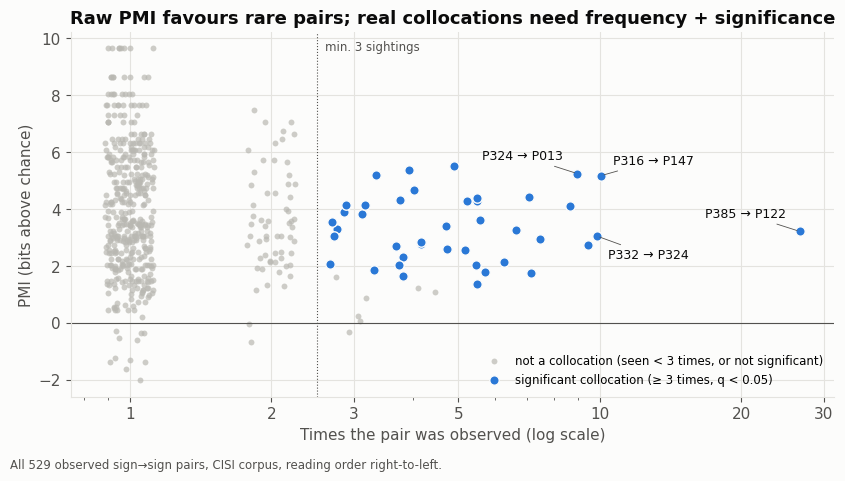

In [37]:
# --- 6d. Figure for the deck: PMI against frequency
fig, ax = plt.subplots(figsize=(8.5, 4.8))
GREY = '#b9b8b2'
jit = np.random.default_rng(3).uniform(-0.12, 0.12, len(coll))
x_all = coll['count'] * np.exp(jit)                     # small jitter so stacked points are visible
is_sig = coll.pair.isin(scored.loc[scored.collocation, 'pair'])
ax.scatter(x_all[~is_sig], coll.PMI[~is_sig], s=18, color=GREY, alpha=0.7, lw=0,
           label='not a collocation (seen < 3 times, or not significant)')
ax.scatter(x_all[is_sig], coll.PMI[is_sig], s=46, color=BLUE, edgecolor=SURFACE, lw=1, zorder=3,
           label='significant collocation (≥ 3 times, q < 0.05)')
ax.axhline(0, color=INK2, lw=0.8)
ax.axvline(2.5, color=INK2, lw=0.8, ls=':')
ax.text(2.6, ax.get_ylim()[1] * 0.97 if ax.get_ylim()[1] > 0 else 7, 'min. 3 sightings', fontsize=8.5, color=INK2, va='top')
xpos = dict(zip(coll.pair, x_all))
label_offsets = {'P385 → P122': (-10, 10, 'right'), 'P316 → P147': (8, 8, 'left'),
                 'P324 → P013': (-10, 10, 'right'), 'P332 → P324': (8, -16, 'left')}
for pair, (dx, dy, ha) in label_offsets.items():
    r = coll.set_index('pair').loc[pair]
    ax.annotate(pair, (xpos[pair], r.PMI), xytext=(dx, dy), textcoords='offset points', fontsize=9,
                color=INK, ha=ha, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.6))
ax.set_xscale('log')
from matplotlib.ticker import FixedLocator, FixedFormatter
ax.xaxis.set_major_locator(FixedLocator([1, 2, 3, 5, 10, 20, 30]))
ax.xaxis.set_major_formatter(FixedFormatter(['1', '2', '3', '5', '10', '20', '30']))
ax.set_xlabel('Times the pair was observed (log scale)')
ax.set_ylabel('PMI (bits above chance)')
ax.set_title('Raw PMI favours rare pairs; real collocations need frequency + significance')
ax.legend(loc='lower right', frameon=False, fontsize=8.5)
fig.text(0.01, 0.01, f'All {len(coll)} observed sign→sign pairs, CISI corpus, reading order right-to-left.',
         fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f'{FIG_DIR}/m2_08_collocations_pmi.png', dpi=200)
plt.show()

In [38]:
# --- 6e. Save
out = coll.merge(scored[['pair', 'q', 'collocation']], on='pair', how='left')
out['collocation'] = out['collocation'].fillna(False)
out.sort_values(['collocation', 'NPMI'], ascending=[False, False]).to_csv(f'{OUT_DIR}/collocations.csv', index=False)
asym.to_csv(f'{OUT_DIR}/pair_order_asymmetry.csv', index=False)
print('saved: outputs/collocations.csv, outputs/pair_order_asymmetry.csv')

saved: outputs/collocations.csv, outputs/pair_order_asymmetry.csv


/sessions/rcw-01kgwsngicncmv17twejjspe/tmp/ipykernel_11/3919264681.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out['collocation'] = out['collocation'].fillna(False)


**Step 6 result.** The collocation index separates genuine sign partnerships from pairs that are common only because both signs are frequent. Frequent pairs overwhelmingly occur in **one order only**, which is further evidence of a fixed writing direction. With this, the Milestone 2 deliverable is complete: the Witten-Bell matrix (Step 4), the directional rules (Step 5) and the collocation indices (Step 6).

## Step 7 — Error propagation: what Milestone 1's mistakes would do to Milestone 2

**Question (from the proposal):** how do image-digitisation errors propagate into the sequence analysis? We simulate Milestone 1's measured error profile on the clean transcriptions, then check which Milestone 2 findings survive.

**Error model.** These rates are derived from Milestone 1's reported measurements on 77 inscription strips, with a ±~13 pp margin from 70 hand-verified detections:

| Error | Derivation | Rate |
|---|---|---|
| **Missed sign** (deletion) | detected 4.9 per text × 86% precision = 4.2 true hits out of 5.6 true signs | ≈ 25% |
| **Extra sign** (insertion) | 4.9 × 14% false positives = 0.69 extra per text ÷ 5.6 | ≈ 12% per true sign |
| **Misread** (substitution) | best recognition top-1 accuracy = 17% | 83% at M1's level |

**Assumptions**
- A misread or inserted sign is drawn uniformly from the 181-sign inventory. This is consistent with M1's collapse check, which found predictions spread over 194 IDs.
- Reading order is correct (M1's right-to-left box ordering worked).
- Segment-edge flags are kept.
- Recognition accuracy is swept from 100% down to M1's 17%, with M1's detection errors held fixed. A "perfect pipeline" reference is shown as well.
- 50 random corruptions per level.

**Findings tracked**
1. Share of genuine endings that are `P324`.
2. Flip test from Step 2 (300 random flips per replicate): is a fixed direction still detected (p < 0.01)?
3. Position-1 entropy gap from Step 5 (start − end, bits).
4. Share of Step 6's 41 collocations still recovered (≥ 3 sightings, q < 0.05).

In [39]:
# --- 7a. Error model and the analyses to re-run on corrupted data
P_DEL = 1 - (4.9 * 0.86) / 5.6            # ≈ 0.25
P_INS = (4.9 * 0.14) / 5.6                # ≈ 0.12
VOCAB = np.array(signs_sorted)
print(f'deletion rate {P_DEL:.3f}   insertion rate {P_INS:.3f} per true sign')

def corrupt(segs, acc, p_del, p_ins, rng):
    out = []
    for sig, ts, te in zip(segs.signs, segs.true_start, segs.true_end):
        new = []
        for s in sig:
            if rng.random() >= p_del:                              # detected
                new.append(s if rng.random() < acc else VOCAB[rng.integers(len(VOCAB))])
            if rng.random() < p_ins:                               # a false box nearby
                new.append(VOCAB[rng.integers(len(VOCAB))])
        if new:
            out.append(dict(signs=new, true_start=ts, true_end=te))
    return pd.DataFrame(out)

clean_colls = set(scored.loc[scored.collocation, 'pair'])

def findings(segs, rng, n_perm=300):
    comp_ = [s for s, a, b in zip(segs.signs, segs.true_start, segs.true_end) if a and b and len(s) >= 2]
    ends = collections.Counter(s[-1] for s in comp_)
    share324 = ends.get('P324', 0) / max(len(comp_), 1)
    # flip test
    F_, L_ = np.array([s[0] for s in comp_]), np.array([s[-1] for s in comp_])
    obs = jsd_bits(collections.Counter(F_), collections.Counter(L_))
    ge = 0
    for _ in range(n_perm):
        f = rng.random(len(comp_)) < 0.5
        ge += jsd_bits(collections.Counter(np.where(f, L_, F_)), collections.Counter(np.where(f, F_, L_))) >= obs
    p_flip = (ge + 1) / (n_perm + 1)
    # position-1 entropy gap
    gap = H_bits(list(F_)) - H_bits(list(L_))
    # collocation recovery
    pc = collections.Counter(p for s in segs.signs for p in zip(s[:-1], s[1:]))
    N_ = sum(pc.values()); lt = collections.Counter(); rt = collections.Counter()
    for (a, b), n in pc.items(): lt[a] += n; rt[b] += n
    cand_ = [(a, b, n) for (a, b), n in pc.items() if n >= 3]
    ps = [fisher_exact([[n, lt[a] - n], [rt[b] - n, N_ - lt[a] - rt[b] + n]], alternative='greater')[1] for a, b, n in cand_]
    qs = bh(ps) if ps else []
    found = {f'{a} → {b}' for (a, b, n), q in zip(cand_, qs) if q < 0.05}
    recall = len(found & clean_colls) / len(clean_colls)
    return dict(share_P324_end=share324, direction_detected=p_flip < 0.01, entropy_gap=gap, colloc_recovered=recall)

# sanity check: with no errors the function must reproduce Steps 2, 5 and 6
base = findings(segments, np.random.default_rng(0))
print('clean data:', {k: round(float(v), 3) for k, v in base.items()})
# (this function uses complete texts only, so compare with the same subset: `comp` from Step 2)
assert abs(base['share_P324_end'] - sum(s[-1] == 'P324' for s in comp) / len(comp)) < 1e-9
assert base['colloc_recovered'] == 1.0 and base['direction_detected']

deletion rate 0.247   insertion rate 0.123 per true sign
clean data: {'share_P324_end': 0.444, 'direction_detected': 1.0, 'entropy_gap': 2.464, 'colloc_recovered': 1.0}


In [40]:
# --- 7b. Sweep recognition accuracy (M1 detection errors held fixed) + a perfect-detection reference
LEVELS = [1.0, 0.9, 0.75, 0.6, 0.45, 0.3, 0.17]
REPS = 50
rng = np.random.default_rng(2026)
sweep = []
for acc in LEVELS:
    for rep in range(REPS):
        noisy = corrupt(segments, acc, P_DEL, P_INS, rng)
        sweep.append(dict(accuracy=acc, detection='M1 detection errors', rep=rep, **findings(noisy, rng)))
for acc in LEVELS:                                     # what recognition errors alone do
    for rep in range(REPS):
        noisy = corrupt(segments, acc, 0.0, 0.0, rng)
        sweep.append(dict(accuracy=acc, detection='perfect detection', rep=rep, **findings(noisy, rng)))
sweep = pd.DataFrame(sweep)

summary7 = (sweep.groupby(['detection', 'accuracy'])
            .agg(P324_end_share=('share_P324_end', 'mean'),
                 direction_detected_pct=('direction_detected', lambda s: 100 * s.mean()),
                 entropy_gap_bits=('entropy_gap', 'mean'),
                 collocations_recovered_pct=('colloc_recovered', lambda s: 100 * s.mean()))
            .round(2).sort_index(level=[0, 1], ascending=[True, False]))
display(summary7)
sweep.to_csv(f'{OUT_DIR}/error_propagation_runs.csv', index=False)

P324_end_share  direction_detected_pct  entropy_gap_bits  collocations_recovered_pct
detection           accuracy                                                                                      
M1 detection errors 1.00                0.31                   100.0              1.22                       44.00
                    0.90                0.28                   100.0              1.09                       32.59
                    0.75                0.23                   100.0              0.80                       20.24
                    0.60                0.19                   100.0              0.62                        9.22
                    0.45                0.14                    80.0              0.41                        3.22
                    0.30                0.10                    30.0              0.23                        0.73
                    0.17                0.06                    12.0              0.13                        0.05
perfect detection   1.00                0.44                   100.0              2.46                      100.00
                    0.90                0.40                   100.0              2.13                       79.61
                    0.75                0.33                   100.0              1.63                       51.85
                    0.60                0.27                   100.0              1.23                       29.07
                    0.45                0.20                   100.0              0.78                       11.12
                    0.30                0.14                    84.0              0.45                        2.68
                    0.17                0.08                    22.0              0.17                        0.24

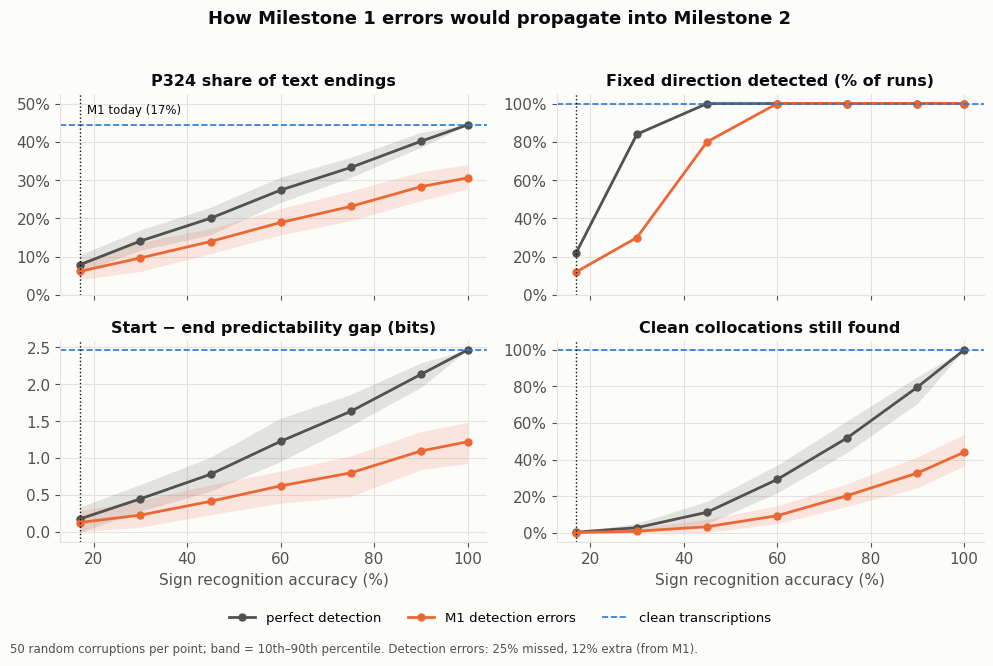

In [41]:
# --- 7c. Figure for the deck: four findings vs recognition accuracy
metrics = [('share_P324_end', 'P324 share of text endings', base['share_P324_end'], 0.5, '{:.0%}'),
           ('direction_detected', 'Fixed direction detected (% of runs)', 1.0, 1, '{:.0%}'),
           ('entropy_gap', 'Start − end predictability gap (bits)', base['entropy_gap'], None, '{:.1f}'),
           ('colloc_recovered', 'Clean collocations still found', 1.0, 1, '{:.0%}')]
fig, axes = plt.subplots(2, 2, figsize=(10, 6.6), sharex=True)
for ax, (col, title, clean_val, ymax, fmt) in zip(axes.flat, metrics):
    for det, color in [('perfect detection', INK2), ('M1 detection errors', ORANGE)]:
        g = sweep[sweep.detection == det].astype({col: float}).groupby('accuracy')[col]
        m = g.mean(); lo10 = g.quantile(0.1); hi90 = g.quantile(0.9)
        if col != 'direction_detected':          # a yes/no outcome has no meaningful percentile band
            ax.fill_between(100 * m.index, lo10, hi90, color=color, alpha=0.15, lw=0)
        ax.plot(100 * m.index, m.values, '-o', color=color, lw=2, ms=5, label=det)
    ax.axhline(clean_val, color=BLUE, lw=1.2, ls='--', label='clean transcriptions')
    ax.axvline(17, color=INK, lw=1, ls=':')
    ax.set_title(title, fontsize=11.5)
    ax.set_ylim(min(0, ax.get_ylim()[0]), ymax * 1.05 if ymax else ax.get_ylim()[1])
    if fmt == '{:.0%}':
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
for ax in axes[1]: ax.set_xlabel('Sign recognition accuracy (%)')
axes[0, 0].text(18.5, 0.5, 'M1 today (17%)', fontsize=8.5, color=INK, ha='left', va='top')   # one label; same line in every panel
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=3, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 0.03))
fig.suptitle('How Milestone 1 errors would propagate into Milestone 2', fontsize=13, fontweight='bold', color=INK)
fig.text(0.01, 0.005, f'{REPS} random corruptions per point; band = 10th–90th percentile. Detection errors: '
         f'{P_DEL:.0%} missed, {P_INS:.0%} extra (from M1).', fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
fig.savefig(f'{FIG_DIR}/m2_09_error_propagation.png', dpi=200)
plt.show()

In [42]:
# --- 7d. Where does each finding break? (first accuracy level at which it is lost, M1 detection errors)
m1 = sweep[sweep.detection == 'M1 detection errors'].groupby('accuracy').mean(numeric_only=True)
def breaks(col, ok):
    bad = [a for a in sorted(m1.index, reverse=True) if not ok(m1.at[a, col])]
    return f'{bad[0]:.0%}' if bad else 'survives to 17%'
br = pd.Series({
    'P324 still the dominant ender (share ≥ 25%)': breaks('share_P324_end', lambda v: v >= 0.25),
    'Fixed direction detected in ≥ 90% of runs': breaks('direction_detected', lambda v: v >= 0.9),
    'Start − end gap ≥ 1 bit': breaks('entropy_gap', lambda v: v >= 1.0),
    'At least half of the collocations recovered': breaks('colloc_recovered', lambda v: v >= 0.5),
}, name='finding first lost at accuracy')
display(br.to_frame())

,finding first lost at accuracy
P324 still the dominant ender (share ≥ 25%),75%
Fixed direction detected in ≥ 90% of runs,45%
Start − end gap ≥ 1 bit,75%
At least half of the collocations recovered,100%


**Step 7 result.**
1. **At M1's current 17% recognition accuracy, almost nothing survives.** Direction is detected in only ~10% of runs, collocation recovery is ≈0%, and P324's share of endings falls from 44% to ~6%.
2. **Findings degrade at different speeds.** The *direction* signal is the most robust: it survives down to about 60% accuracy even with M1's detection errors. Fine-grained *collocations* are the most fragile: they need near-perfect recognition.
3. **"Solved" detection is not good enough for sequence statistics.** Even with 100% recognition, M1's detection errors alone (25% missed, 12% extra boxes) cut collocation recovery to ~44% and halve the start–end gap. A missed or extra box breaks every pair it touches.

This quantifies the pipeline's weakest link, justifies running Milestones 2–4 on expert transcriptions, and gives concrete targets for future work on Milestone 1.

## Step 8 — Results summary

Every headline number below is computed from the live variables above, not typed in, so this summary cannot drift out of step with the analysis. It is also saved to `outputs/results_summary.json`.

In [43]:
# --- 8a. Collect the headline results
m1_tab = sweep[sweep.detection == 'M1 detection errors'].groupby('accuracy').mean(numeric_only=True)
results = {
    'corpus': {'texts': int(len(texts)), 'sign_tokens': int(real_tokens), 'distinct_signs': int(len(freq)),
               'complete_single_line_texts': int(len(complete)), 'P000_breaks': int((raw.sign == BREAK).sum()),
               'two_line_texts': int(texts.multiline.sum())},
    'step1_sanity': {'mean_length': round(float(L.mean()), 2), 'median_length': float(L.median()),
                     'signs_for_50pct': signs_for(0.5), 'signs_for_80pct': signs_for(0.8),
                     'top67_coverage_pct': round(100 * float(cum.iloc[66]), 1), 'hapax_signs': hapax},
    'step2_positions': {'distinct_beginners': int(len(begin)), 'distinct_enders': int(len(end)),
                        'top_beginner': begin.index[0], 'top_beginner_share_pct': round(100 * begin.iloc[0] / begin.sum(), 1),
                        'top_ender': end.index[0], 'top_ender_share_pct': round(100 * end.iloc[0] / end.sum(), 1),
                        'entropy_begin_bits': round(entropy_bits(begin), 2), 'entropy_end_bits': round(entropy_bits(end), 2),
                        'flip_test_jsd': round(float(observed), 3), 'flip_test_null_max': round(float(null.max()), 3),
                        'flip_test_p': f'< {1 / N_PERM:.4f}' if (null >= observed).sum() == 0 else round(float(p_value), 4)},
    'step3_matrix': {'transitions': len(pairs), 'cells': int(possible), 'observed_cells': observed_cells,
                     'zero_cells_pct': round(100 * (1 - observed_cells / possible), 2),
                     'single_observation_rows': int((rows_n == 1).sum()),
                     'rows_mle_100pct_certain': int((P_mle.max(axis=1) == 1).sum())},
    'step4_smoothing': {m: {'zero_prob_events': int(r['zero-probability events']),
                            'perplexity': r['perplexity (mean)'] if np.isfinite(r['perplexity (mean)']) else 'infinite (fails)'}
                        for m, r in cv_summary.iterrows()},
    'step5_direction': {'forward_vs_backward_training_bits': [round(train_rtl['bits_per_transition'], 4),
                                                             round(train_ltr['bits_per_transition'], 4)],
                        'forward_vs_backward_heldout_perplexity': [round(2 ** cv_rtl, 2), round(2 ** cv_ltr, 2)],
                        'entropy_pos1_from_start': round(from_start[0], 2), 'entropy_pos1_from_end': round(from_end[0], 2),
                        'entropy_pos2_from_start': round(from_start[1], 2), 'pos1_gap_p': f'< {1 / N_PERM:.4f}',
                        'roles': {r: list(rules.index[rules.role == r]) for r in ['OPENER', 'ENDER', 'MEDIAL']}},
    'step6_collocations': {'distinct_pairs': int(len(coll)), 'scored_pairs': int(len(scored)),
                           'significant': int(scored.collocation.sum()),
                           'top5_by_npmi': list(scored[scored.collocation].sort_values('NPMI', ascending=False).pair.head(5)),
                           'frequent_pairs_one_order_only': f'{int((asym.reverse == 0).sum())} of {len(asym)}',
                           'one_order_significant': int((asym.q < 0.05).sum())},
    'step7_error_propagation': {'deletion_rate': round(P_DEL, 3), 'insertion_rate': round(P_INS, 3),
                                'at_M1_accuracy_17pct': {k: round(float(m1_tab.at[0.17, k]), 3) for k in
                                                         ['share_P324_end', 'direction_detected', 'entropy_gap', 'colloc_recovered']},
                                'perfect_recognition_with_M1_detection': {k: round(float(m1_tab.at[1.0, k]), 3) for k in
                                                         ['share_P324_end', 'entropy_gap', 'colloc_recovered']},
                                'first_lost_at': br.to_dict()},
}
with open(f'{OUT_DIR}/results_summary.json', 'w') as f:
    json.dump(results, f, indent=2, default=str)
print(json.dumps(results, indent=2, default=str))

{
  "corpus": {
    "texts": 179,
    "sign_tokens": 984,
    "distinct_signs": 181,
    "complete_single_line_texts": 154,
    "P000_breaks": 19,
    "two_line_texts": 7
  },
  "step1_sanity": {
    "mean_length": 5.57,
    "median_length": 5.0,
    "signs_for_50pct": 17,
    "signs_for_80pct": 58,
    "top67_coverage_pct": 83.4,
    "hapax_signs": 77
  },
  "step2_positions": {
    "distinct_beginners": 86,
    "distinct_enders": 30,
    "top_beginner": "P385",
    "top_beginner_share_pct": 17.5,
    "top_ender": "P324",
    "top_ender_share_pct": 45.3,
    "entropy_begin_bits": 5.63,
    "entropy_end_bits": 3.22,
    "flip_test_jsd": 0.891,
    "flip_test_null_max": 0.418,
    "flip_test_p": "< 0.0001"
  },
  "step3_matrix": {
    "transitions": 1123,
    "cells": 33124,
    "observed_cells": 645,
    "zero_cells_pct": 98.05,
    "single_observation_rows": 73,
    "rows_mle_100pct_certain": 84
  },
  "step4_smoothing": {
    "MLE (no smoothing)": {
      "zero_prob_events": 516,
   

In [44]:
# --- 8b. Inventory of deliverables
deliv = []
for root, _, files in os.walk(OUT_DIR):
    for fn in sorted(files):
        p = os.path.join(root, fn); deliv.append((p, f'{os.path.getsize(p)/1024:.0f} KB'))
display(pd.DataFrame(deliv, columns=['file', 'size']))

,file,size
0,outputs/collocations.csv,37 KB
1,outputs/directional_rules.csv,2 KB
2,outputs/error_propagation_runs.csv,58 KB
3,outputs/markov_counts.csv,66 KB
4,outputs/markov_mle.csv,222 KB
5,outputs/markov_witten_bell.csv,293 KB
6,outputs/pair_order_asymmetry.csv,1 KB
7,outputs/results_summary.json,3 KB
8,outputs/segments_rtl.json,31 KB
9,outputs/texts_reading_order.csv,9 KB


## Milestone 2 — conclusions

1. **The script has a fixed writing direction.** Texts begin and end in statistically different ways (flip test p < 0.0001; the ending is ~2.4 bits more predictable than the beginning). Frequent sign pairs occur in one order only. All findings are consistent with right-to-left reading.
2. **Positional syntax exists.** There is a small class of significant **enders** (`P324`, `P217`, `P086`, `P013`), **openers** (`P385`, `P378`, `P256`) and **medial-only** signs (`P122`, `P050`, `P120`, `P062`, `P060`).
3. **The Markov matrix is extremely sparse** (98% of cells unseen). **Witten-Bell smoothing** is necessary and validated: plain MLE fails on 46% of held-out transitions, and Witten-Bell halves add-one's perplexity (≈41 vs ≈77).
4. **Overall perplexity cannot detect direction.** Forward and backward bigram models are mathematically identical on training data. Claims of direction based on it are empty, which is a lesson that carries into Milestone 4.
5. **41 significant collocations** were identified with PMI, a frequency floor and significance testing. Raw PMI alone would have favoured one-off accidents.
6. **Error propagation.** At Milestone 1's 17% recognition accuracy, none of these findings could be recovered from automated readings. Direction needs about ≥ 60% recognition accuracy, collocations need near-perfect recognition *and* better detection.